# Telco customer churn: who to contact, with what action, and what it is worth

**Business question:** *which customers should a retention team contact this month, with what action, and what is that worth?*

**Data:** the public IBM *Telco Customer Churn* dataset (Kaggle): 7,043 customers, 21 columns, one snapshot.

**Framing.** The model gives each active customer a **churn-risk score**: how closely they resemble customers who left. The data is a single snapshot without dates, so this is a resemblance score, not a literal next-month forecast.
- Customers are ranked by **risk × value**. The contact budget decides how far down the list to go.
- Actions differ by tier: high risk/value → call, medium → CRM email/SMS, the rest → no outreach.
- Missing a churner is assumed to cost more than an unnecessary offer, so accuracy and the 0.5 cut-off are not used. Success is the **€ value of the contact list**, compared with random selection and a simple business rule.
- **Currency:** the data does not state one; amounts are shown in €.

**Headline results** (held-out test set of 1,409 customers, used once):

| | |
|---|---|
| Top 20% by risk | 68% are real leavers (random: 27%); reaches 52% of all churners |
| Model vs rule "month-to-month & tenure ≤ 6" | same 291 contacts: 194 vs 170 churners (+14%) |
| Best list (risk × value, base assumptions) | top 23% → ≈ €4,750 per 1,000 customers per monthly campaign, ≈ 4× the rule |
| Logistic regression vs XGBoost (nested CV) | PR-AUC 0.673 vs 0.668, ROC-AUC 0.850 vs 0.849: tied, so the explainable model was chosen |

**Contents**
1. Setup · 2. Data audit · 3. Train/test split and EDA (with hypotheses) · 4. Preprocessing · 5. Model comparison · 6. Final model · 7. Hypothesis tests · 8. Business translation · 9. Limitations and next steps

## 1. Setup
Python 3.13; library versions are printed for reproducibility.
One main seed, `RANDOM_STATE = 42`, is passed explicitly to every split, CV and model. Five robustness seeds are fixed in advance and used only to check stability, never to choose a model.

In [1]:
# ============================================================
# 1. SETUP
# ============================================================
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import statsmodels
import xgboost

# Print versions so every result can be traced back to an exact environment
print(f"Python       {sys.version.split()[0]}")
for lib in [np, pd, matplotlib, sns, sklearn, statsmodels, xgboost]:
    print(f"{lib.__name__:12s} {lib.__version__}")

Python       3.13.16
numpy        2.5.3
pandas       2.3.3
matplotlib   3.11.2
seaborn      0.13.2
sklearn      1.9.1
statsmodels  0.15.0
xgboost      3.4.1


In [2]:
# Works whether the notebook is run from the repository root or from a notebooks/ folder.
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
for folder in (FIG_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)   # safe if the folder already exists

DATA_PATH = DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

print("Project root:", PROJECT_ROOT)
print("Data file found:", DATA_PATH.exists())

Project root: .
Data file found: True


In [3]:
# Main seed: passed explicitly to every split, CV and model.
# scikit-learn does NOT reliably follow np.random.seed(), so we always pass random_state.
RANDOM_STATE = 42

# Robustness seeds: fixed now, before seeing any results, so no seed can be picked
# because it happens to look good. Used only in section 6 to check stability.
ROBUSTNESS_SEEDS = [0, 7, 99, 123, 2026]

np.random.seed(RANDOM_STATE)   # covers any plain numpy randomness

In [4]:
# Load the raw file exactly as downloaded; no cleaning yet.
df_raw = pd.read_csv(DATA_PATH)

# The Kaggle page lists 7,043 customers x 21 columns: this confirms we have the right file.
print("Shape:", df_raw.shape)
print("Columns:", df_raw.columns.tolist())

Shape: (7043, 21)
Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


## 2. Data audit
Nine checks: types, missing and hidden blanks, duplicates, category levels, coding, numeric ranges, target, redundancy, leakage.
**Rule:** only "safe" fixes here, meaning fixed row-by-row rules that learn nothing from the data. Anything learned from data waits for the section 4 pipeline.

**Findings**
- 11 hidden blanks in `TotalCharges` are exactly the 11 tenure-0 customers (none churned).
- Churn is 26.5%, so predicting "nobody leaves" would already be 73.5% accurate.
- No duplicate customers. 73 customers share identical profiles, and 18 of those 33 profiles have mixed outcomes: some churn cannot be predicted from this data.
- "No internet/phone service" exactly repeats `InternetService` / `PhoneService`.
- `TotalCharges` ≈ tenure × `MonthlyCharges` (correlation 0.9996).

**Leakage note:** for churners, tenure and `TotalCharges` reflect their whole stay up to leaving.

In [5]:
# Work on a copy so df_raw always stays exactly as downloaded (useful for comparison)
df = df_raw.copy()

# Check 1: data types. We expect tenure, MonthlyCharges and TotalCharges to be numeric
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [6]:
# Real missing values (NaN) that pandas recognises
nan_counts = df.isna().sum()

# Hidden blanks: text cells that are empty or contain only spaces.
# pandas does NOT count these as missing, which is why they're easy to miss.
text_cols = df.select_dtypes(include="object").columns
blank_counts = df[text_cols].apply(lambda s: s.str.strip().eq("").sum())

missing = pd.DataFrame({"NaN": nan_counts, "hidden_blank": blank_counts}).fillna(0).astype(int)
problem_cols = missing[missing.sum(axis=1) > 0]
print(problem_cols if not problem_cols.empty else "No NaN or hidden blanks found")

              NaN  hidden_blank
TotalCharges    0            11


In [7]:
# Exact duplicate rows would mean the same customer counted twice
print("Duplicate full rows:      ", df.duplicated().sum())

# Each customerID should be unique; repeats could leak between train and test
print("Duplicate customerIDs:    ", df["customerID"].duplicated().sum())

# Identical profiles apart from the ID: NOT necessarily an error
# (two customers can have the same plan), but good to know
print("Duplicate profiles (no ID):", df.drop(columns="customerID").duplicated().sum())

Duplicate full rows:       0
Duplicate customerIDs:     0
Duplicate profiles (no ID): 22


In [8]:
# Show every level and its count for each text column (excluding the ID and
# TotalCharges, which should be numeric). Odd levels like "No internet service" show up here.
cat_cols = [c for c in text_cols if c not in ["customerID", "TotalCharges"]]
for col in cat_cols:
    print(f"{col:17s} {df[col].value_counts().to_dict()}")

# SeniorCitizen is the only demographic stored as 1/0 instead of Yes/No
print(f"\n{'SeniorCitizen':17s} {df['SeniorCitizen'].value_counts().to_dict()}")

gender            {'Male': 3555, 'Female': 3488}
Partner           {'No': 3641, 'Yes': 3402}
Dependents        {'No': 4933, 'Yes': 2110}
PhoneService      {'Yes': 6361, 'No': 682}
MultipleLines     {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService   {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity    {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup      {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection  {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport       {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV       {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies   {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract          {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling  {'Yes': 4171, 'No': 2872}
PaymentMethod     {'Electronic check': 2365, 'Mailed check': 1612, 'Bank transfer (automatic)': 1544, 'Credit card (automatic

In [9]:
# SAFE FIX: turn blank/space-only text into NaN, then convert to numbers.
# errors="coerce" is deliberately NOT used: any OTHER non-numeric value should raise an
# error instead of silently becoming NaN.
# Read from df_raw (never modified), so this cell gives the same result however often it runs
df["TotalCharges"] = pd.to_numeric(df_raw["TotalCharges"].str.strip().replace("", np.nan))
print("TotalCharges missing after conversion:", df["TotalCharges"].isna().sum())

# Ranges of the numeric columns
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print(df[num_cols].describe().T)

# Who are the missing-TotalCharges customers? Check the "all tenure 0" claim ourselves
print("\nTenure of rows with missing TotalCharges:",
      df.loc[df["TotalCharges"].isna(), "tenure"].value_counts().to_dict())
print("Customers with tenure 0:", (df["tenure"] == 0).sum())

# Check the reported spike at the maximum tenure (possible cap)
print("Customers at max tenure", df["tenure"].max(), ":", (df["tenure"] == df["tenure"].max()).sum())

TotalCharges missing after conversion: 11
                 count         mean          std    min     25%       50%  \
tenure          7043.0    32.371149    24.559481   0.00    9.00    29.000   
MonthlyCharges  7043.0    64.761692    30.090047  18.25   35.50    70.350   
TotalCharges    7032.0  2283.300441  2266.771362  18.80  401.45  1397.475   

                      75%      max  
tenure            55.0000    72.00  
MonthlyCharges    89.8500   118.75  
TotalCharges    3794.7375  8684.80  

Tenure of rows with missing TotalCharges: {0: 11}
Customers with tenure 0: 11
Customers at max tenure 72 : 362


In [10]:
# Confirm the ~27% churn rate reported on the dataset page
print(df["Churn"].value_counts().to_dict())
print(df["Churn"].value_counts(normalize=True).round(4).to_dict())

# SAFE FIX: Yes/No -> 1/0 (a fixed rule that learns nothing from the data).
# The assert stops us if any unexpected label exists.
df["Churn"] = df_raw["Churn"].map({"Yes": 1, "No": 0})
assert df["Churn"].isna().sum() == 0, "Unexpected Churn labels found"

# Do the tenure-0 customers churn? (Not yet a decision, just a fact for section 4)
print("\nChurn among tenure-0 customers:", df.loc[df["tenure"] == 0, "Churn"].value_counts().to_dict())

{'No': 5174, 'Yes': 1869}
{'No': 0.7346, 'Yes': 0.2654}

Churn among tenure-0 customers: {0: 11}


In [11]:
# Is TotalCharges basically tenure x MonthlyCharges? Exclude tenure 0 to avoid dividing by 0
has_tenure = df["tenure"] > 0
approx_total = df.loc[has_tenure, "tenure"] * df.loc[has_tenure, "MonthlyCharges"]
ratio = df.loc[has_tenure, "TotalCharges"] / approx_total
print("Correlation TotalCharges vs tenure*MonthlyCharges:",
      round(df.loc[has_tenure, "TotalCharges"].corr(approx_total), 4))
print("Ratio TotalCharges / (tenure*MonthlyCharges):")
print(ratio.describe().round(3))

# Is "No internet service" just a repeat of InternetService == "No"?
internet_addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies"]
no_internet = df["InternetService"] == "No"
for col in internet_addons:
    matches = (no_internet == (df[col] == "No internet service")).all()
    print(f"{col:17s} 'No internet service' exactly matches InternetService=No: {matches}")

# Same question for "No phone service" vs PhoneService == "No"
matches = ((df["PhoneService"] == "No") == (df["MultipleLines"] == "No phone service")).all()
print(f"{'MultipleLines':17s} 'No phone service' exactly matches PhoneService=No: {matches}")

Correlation TotalCharges vs tenure*MonthlyCharges: 0.9996
Ratio TotalCharges / (tenure*MonthlyCharges):
count    7032.000
mean        1.000
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.020
max         1.573
dtype: float64
OnlineSecurity    'No internet service' exactly matches InternetService=No: True
OnlineBackup      'No internet service' exactly matches InternetService=No: True
DeviceProtection  'No internet service' exactly matches InternetService=No: True
TechSupport       'No internet service' exactly matches InternetService=No: True
StreamingTV       'No internet service' exactly matches InternetService=No: True
StreamingMovies   'No internet service' exactly matches InternetService=No: True
MultipleLines     'No phone service' exactly matches PhoneService=No: True


In [12]:
# SAFE FIX: move customerID into the index. It is never a model input
# (a model could memorise IDs), but we KEEP it, because the business
# deliverable is a list of WHICH customers to contact.
# Only move customerID into the index if that hasn't happened yet
if "customerID" in df.columns:
    df = df.set_index("customerID")

print("Shape after audit fixes:", df.shape)
print(df.dtypes.value_counts().to_dict())

Shape after audit fixes: (7043, 20)
{dtype('O'): 15, dtype('int64'): 3, dtype('float64'): 2}


In [13]:
# Mark ALL customers involved in a repeated profile (keep=False marks every copy, not just the repeats)
profile_cols = [c for c in df_raw.columns if c not in ["customerID", "Churn"]]
dup_mask = df_raw.duplicated(subset=profile_cols, keep=False)
print("Customers involved in a repeated profile:", dup_mask.sum())

# Look at them side by side: are they simple, low-tenure plans?
cols = ["customerID", "tenure", "Contract", "PhoneService", "InternetService",
        "MonthlyCharges", "TotalCharges", "Churn"]
print(df_raw.loc[dup_mask, cols].sort_values(["tenure", "MonthlyCharges"]).to_string())

# Do identical profiles ever have DIFFERENT churn outcomes?
outcomes = df_raw[dup_mask].groupby(profile_cols)["Churn"].nunique()
print("\nNumber of distinct profiles:", len(outcomes))
print("Profiles where identical customers had different churn outcomes:", (outcomes > 1).sum())

Customers involved in a repeated profile: 73
      customerID  tenure        Contract PhoneService InternetService  MonthlyCharges TotalCharges Churn
1736  7551-JOHTI       1  Month-to-month          Yes              No           19.50         19.5   Yes
4172  1905-OEILC       1  Month-to-month          Yes              No           19.50         19.5    No
542   2866-IKBTM       1  Month-to-month          Yes              No           19.55        19.55    No
710   1029-QFBEN       1  Month-to-month          Yes              No           19.55        19.55   Yes
1491  8605-ITULD       1  Month-to-month          Yes              No           19.55        19.55    No
6449  7601-WFVZV       1  Month-to-month          Yes              No           19.55        19.55    No
1049  8329-IBCTI       1  Month-to-month          Yes              No           19.65        19.65   Yes
5170  7721-DVEKZ       1  Month-to-month          Yes              No           19.65        19.65    No
5446  6141

## 3. Train/test split and EDA
The data is split **first**, as in production: 80/20, stratified on churn, seed 42 (train 5,634, test 1,409). All EDA uses the training data only; the test set stays untouched until the final evaluation.
Charts show the churn rate per group **with the group size**, against the overall rate.

In [14]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20

# Split FIRST, as in production: the test set plays the role of "future customers"
# and must not influence any choice we make from here on.
# stratify keeps the churn rate (~26.5%) the same in both parts.
train_df, test_df = train_test_split(
    df, test_size=TEST_SIZE, stratify=df["Churn"], random_state=RANDOM_STATE
)

print("Train:", train_df.shape, "| churn rate:", round(train_df["Churn"].mean(), 4))
print("Test: ", test_df.shape, "| churn rate:", round(test_df["Churn"].mean(), 4))

# Save which customers are in the test set, so the exact split can be reproduced or audited later
pd.Series(test_df.index, name="customerID").to_csv(RESULTS_DIR / "test_ids.csv", index=False)

# From here on: EDA uses train_df ONLY. test_df is not touched until the final evaluation.

Train: (5634, 20) | churn rate: 0.2654
Test:  (1409, 20) | churn rate: 0.2654


In [15]:
# A separate copy for EDA, so chart-only columns (like tenure bands) never end up in the model data
train_eda = train_df.copy()
overall_rate = train_eda["Churn"].mean()

def churn_rate_bar(data, col, title, order=None, filename=None):
    """Bar chart of churn rate per group, with group size, plus the overall churn line."""
    # Churn rate (mean of 0/1) and number of customers per group
    summary = data.groupby(col, observed=True)["Churn"].agg(rate="mean", n="size")
    if order is not None:
        summary = summary.reindex(order)

    fig, ax = plt.subplots(figsize=(7, 4))
    bars = ax.bar(summary.index.astype(str), summary["rate"] * 100, color="#4C72B0")
    # The overall rate as a reference line: a bar above it means "riskier than average"
    ax.axhline(overall_rate * 100, color="grey", linestyle="--", label=f"Overall {overall_rate:.1%}")
    # Show rate AND group size: 60% of 20 people means much less than 40% of 3,000
    for bar, (rate, n) in zip(bars, summary.itertuples(index=False)):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
                f"{rate:.0%}\nn={n:,}", ha="center", va="bottom", fontsize=9)
    ax.set_ylabel("Churn rate (%)")
    ax.set_title(title)
    ax.set_ylim(0, max(summary["rate"].max() * 125, overall_rate * 150))
    ax.legend(loc="upper right")
    plt.xticks(rotation=15)
    plt.tight_layout()
    if filename:
        fig.savefig(FIG_DIR / filename, dpi=200)   # saved to outputs/figures
    plt.show()

    # Print the numbers too, so we interpret real values, not bar heights
    print(summary.assign(rate_pct=(summary["rate"] * 100).round(1))[["n", "rate_pct"]].to_string())
    return summary

### Chart 1 – Contract type
Month-to-month 42.7% vs one-year 11.1% vs two-year 2.9%. Caveat: selection and contract lock-in, not proof that contracts cause loyalty.

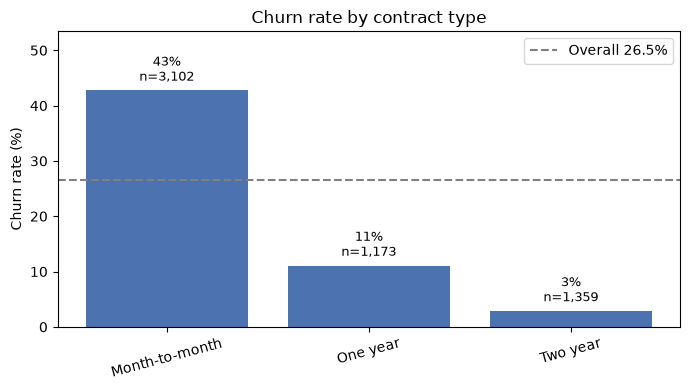

                   n  rate_pct
Contract                      
Month-to-month  3102      42.7
One year        1173      11.1
Two year        1359       2.9


,rate,n
Contract,,
Month-to-month,0.427466,3102
One year,0.110827,1173
Two year,0.028698,1359


In [16]:
contract_order = ["Month-to-month", "One year", "Two year"]
churn_rate_bar(train_eda, "Contract", "Churn rate by contract type",
               order=contract_order, filename="eda_1_contract.png")

### Chart 2 – Tenure bands and the 72-month spike
Risk falls from 52% (0–6 months) to 10% (49–72). Biggest single spike: churners in month 1. The spike at 72 may be a cap or an early cohort (cannot tell).

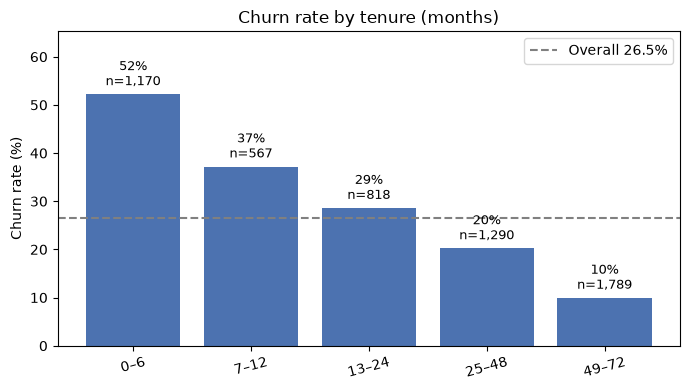

                n  rate_pct
tenure_band                
0–6          1170      52.2
7–12          567      37.2
13–24         818      28.6
25–48        1290      20.2
49–72        1789       9.9


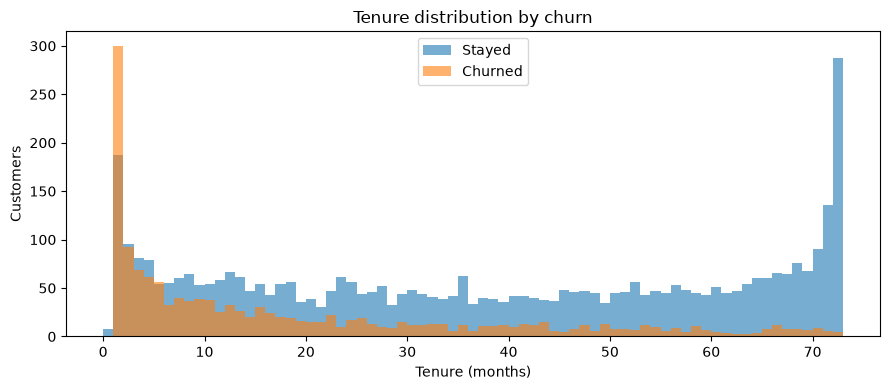

Customers per tenure month, 66–72:
{66: 78, 67: 73, 68: 84, 69: 75, 70: 99, 71: 142, 72: 292}


In [17]:
# Bands chosen for readability (first half-year, first year, etc.); for charts only
tenure_bins = [-1, 6, 12, 24, 48, 72]
tenure_labels = ["0–6", "7–12", "13–24", "25–48", "49–72"]
train_eda["tenure_band"] = pd.cut(train_eda["tenure"], bins=tenure_bins, labels=tenure_labels)

churn_rate_bar(train_eda, "tenure_band", "Churn rate by tenure (months)",
               order=tenure_labels, filename="eda_2_tenure_bands.png")

# One bar per month, to see whether 72 is a real spike compared with 70 and 71 (possible cap)
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(0, 74)
ax.hist(train_eda.loc[train_eda["Churn"] == 0, "tenure"], bins=bins, alpha=0.6, label="Stayed")
ax.hist(train_eda.loc[train_eda["Churn"] == 1, "tenure"], bins=bins, alpha=0.6, label="Churned")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Customers")
ax.set_title("Tenure distribution by churn")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_2b_tenure_hist.png", dpi=200)
plt.show()

print("Customers per tenure month, 66–72:")
print(train_eda["tenure"].value_counts().sort_index().loc[66:72].to_dict())

### Chart 3 – Monthly charges
Churners pay more (median 80 vs 64), but the pattern is not linear and is mixed up with product type (fiber).

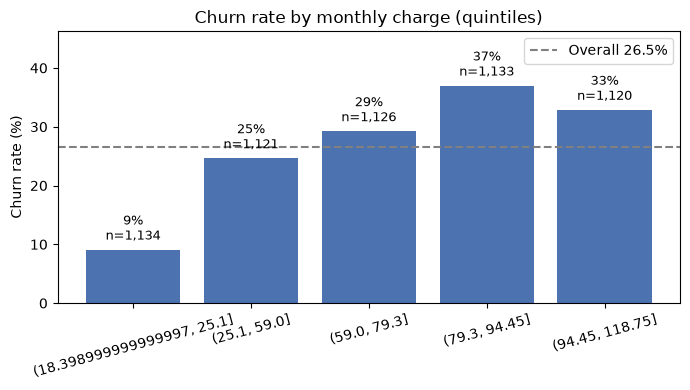

                               n  rate_pct
charge_band                               
(18.398999999999997, 25.1]  1134       9.1
(25.1, 59.0]                1121      24.6
(59.0, 79.3]                1126      29.2
(79.3, 94.45]               1133      37.0
(94.45, 118.75]             1120      32.9

Median MonthlyCharges: {0: 64.4, 1: 79.95}


In [18]:
# Five equal-sized groups (quintiles), so every bar has about the same number of customers
train_eda["charge_band"] = pd.qcut(train_eda["MonthlyCharges"], q=5)
churn_rate_bar(train_eda, "charge_band", "Churn rate by monthly charge (quintiles)",
               filename="eda_3_monthly_charges.png")

print("\nMedian MonthlyCharges:",
      train_eda.groupby("Churn")["MonthlyCharges"].median().round(2).to_dict())

### Chart 4 – Internet service
Fiber 42% vs DSL 19% vs no internet 7%: the premium product loses the most customers.

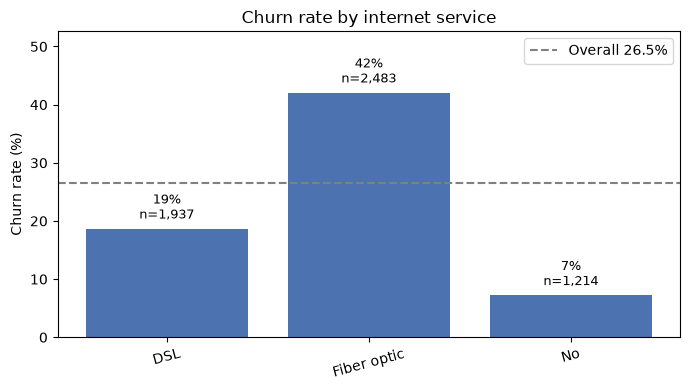

                    n  rate_pct
InternetService                
DSL              1937      18.7
Fiber optic      2483      42.1
No               1214       7.2


,rate,n
InternetService,,
DSL,0.186887,1937
Fiber optic,0.420862,2483
No,0.072488,1214


In [19]:
churn_rate_bar(train_eda, "InternetService", "Churn rate by internet service",
               order=["DSL", "Fiber optic", "No"], filename="eda_4_internet.png")

### Chart 5 – Payment method
Electronic check 46% vs automatic payments 15–16%.

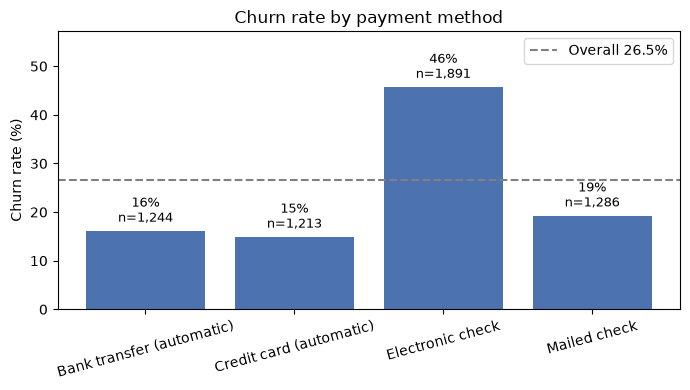

                              n  rate_pct
PaymentMethod                            
Bank transfer (automatic)  1244      16.2
Credit card (automatic)    1213      14.9
Electronic check           1891      45.7
Mailed check               1286      19.3


,rate,n
PaymentMethod,,
Bank transfer (automatic),0.161576,1244
Credit card (automatic),0.149217,1213
Electronic check,0.457430,1891
Mailed check,0.192846,1286


In [20]:
churn_rate_bar(train_eda, "PaymentMethod", "Churn rate by payment method",
               filename="eda_5_payment.png")

### Chart 6 – Protective add-ons
Without online security / tech support ~42% vs ~15% with them (among internet customers).

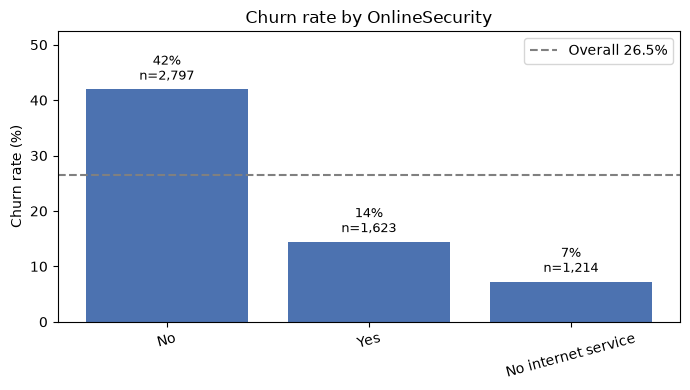

                        n  rate_pct
OnlineSecurity                     
No                   2797      41.9
Yes                  1623      14.4
No internet service  1214       7.2


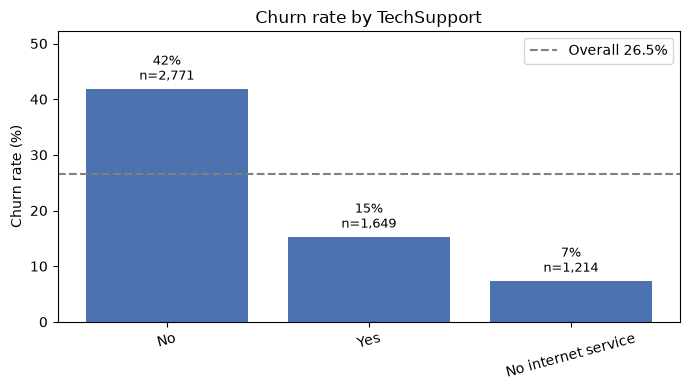

                        n  rate_pct
TechSupport                        
No                   2771      41.8
Yes                  1649      15.2
No internet service  1214       7.2


In [21]:
addon_order = ["No", "Yes", "No internet service"]
for col in ["OnlineSecurity", "TechSupport"]:
    churn_rate_bar(train_eda, col, f"Churn rate by {col}",
                   order=addon_order, filename=f"eda_6_{col}.png")

### Chart 7 – Contract × tenure heatmap
Both signals matter: within month-to-month, risk falls 54% → 28% with tenure; at the same tenure, contracts stay far lower. Riskiest group: new month-to-month customers (n = 1,122, 54%).

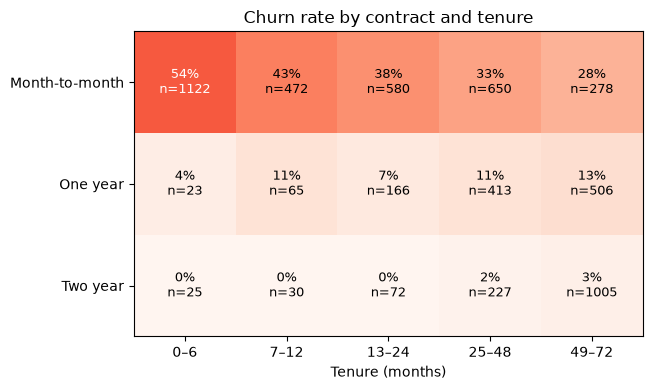

tenure_band      0–6  7–12  13–24  25–48  49–72
Contract                                       
Month-to-month  54.4  43.2   38.3   32.8   27.7
One year         4.3  10.8    7.2   10.7   13.0
Two year         0.0   0.0    0.0    1.8    3.5
tenure_band      0–6  7–12  13–24  25–48  49–72
Contract                                       
Month-to-month  1122   472    580    650    278
One year          23    65    166    413    506
Two year          25    30     72    227   1005


In [22]:
# Do the two signals overlap, or add up? Each cell = churn rate and size of that combination
rate_tab = train_eda.pivot_table(index="Contract", columns="tenure_band", values="Churn",
                                 aggfunc="mean", observed=True).reindex(contract_order)
n_tab = train_eda.pivot_table(index="Contract", columns="tenure_band", values="Churn",
                              aggfunc="count", observed=True).reindex(contract_order)

fig, ax = plt.subplots(figsize=(8, 4))
ax.imshow(rate_tab.values * 100, cmap="Reds", vmin=0, vmax=100)
ax.set_xticks(range(len(rate_tab.columns)), labels=rate_tab.columns)
ax.set_yticks(range(len(rate_tab.index)), labels=rate_tab.index)
for i in range(rate_tab.shape[0]):
    for j in range(rate_tab.shape[1]):
        rate, n = rate_tab.iloc[i, j], n_tab.iloc[i, j]
        if pd.notna(rate):   # skip combinations with no customers
            ax.text(j, i, f"{rate:.0%}\nn={int(n)}", ha="center", va="center", fontsize=9,
                    color="white" if rate > 0.5 else "black")
ax.set_xlabel("Tenure (months)")
ax.set_title("Churn rate by contract and tenure")
plt.tight_layout()
fig.savefig(FIG_DIR / "eda_7_contract_x_tenure.png", dpi=200)
plt.show()

print((rate_tab * 100).round(1).to_string())
print(n_tab.to_string())

### Chart 8 – Price-change ratio (our own idea)
Ratio = TotalCharges ÷ (tenure × MonthlyCharges). Weak, mixed pattern (any change, not just increases).

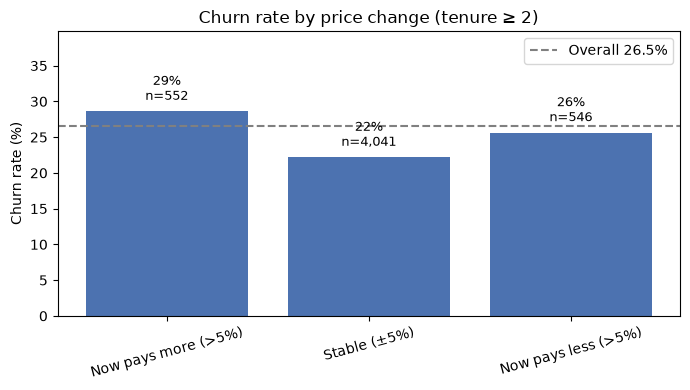

                        n  rate_pct
price_change                       
Now pays more (>5%)   552      28.6
Stable (±5%)         4041      22.2
Now pays less (>5%)   546      25.6


,rate,n
price_change,,
Now pays more (>5%),0.286232,552
Stable (±5%),0.221975,4041
Now pays less (>5%),0.256410,546


In [23]:
# Only customers with tenure >= 2: with 1 month of history the ratio is always exactly 1,
# so including them would just add "new customers" to the Stable group
eligible = train_eda["tenure"] >= 2
ratio = train_eda.loc[eligible, "TotalCharges"] / (
    train_eda.loc[eligible, "tenure"] * train_eda.loc[eligible, "MonthlyCharges"])

# ratio < 0.95: pays clearly MORE now than their past average; > 1.05: pays clearly LESS now
price_labels = ["Now pays more (>5%)", "Stable (±5%)", "Now pays less (>5%)"]
price_change = pd.cut(ratio, bins=[0, 0.95, 1.05, np.inf], labels=price_labels)

churn_rate_bar(train_eda.loc[eligible].assign(price_change=price_change), "price_change",
               "Churn rate by price change (tenure ≥ 2)", order=price_labels,
               filename="eda_8_price_change.png")

### Chart 9 – Demographics
Seniors 41% vs 24%; no partner 33% vs 20%; no dependents 31% vs 15%; **gender: no difference (27% vs 26%)**.

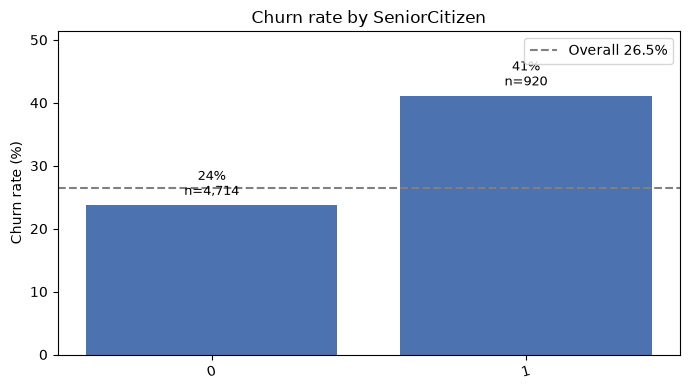

                  n  rate_pct
SeniorCitizen                
0              4714      23.7
1               920      41.1


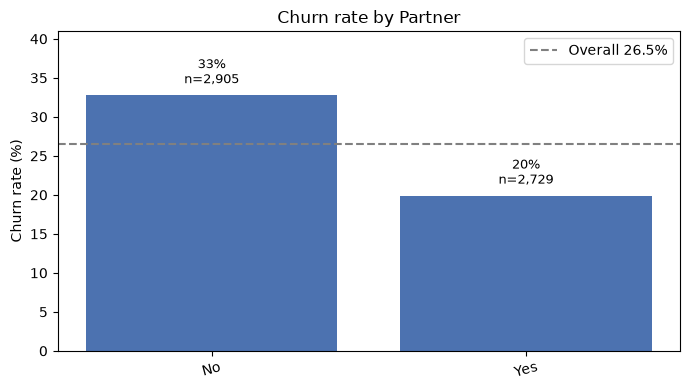

            n  rate_pct
Partner                
No       2905      32.8
Yes      2729      19.9


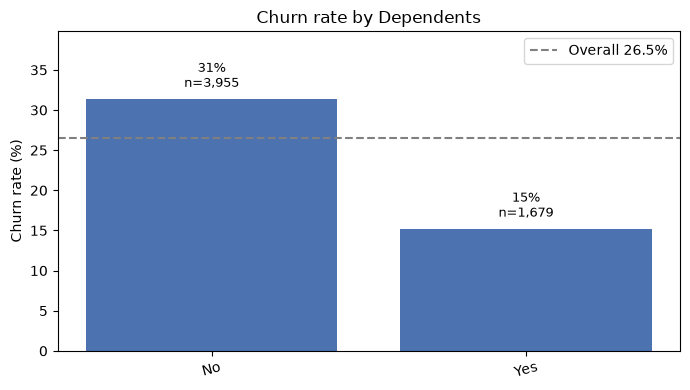

               n  rate_pct
Dependents                
No          3955      31.4
Yes         1679      15.2


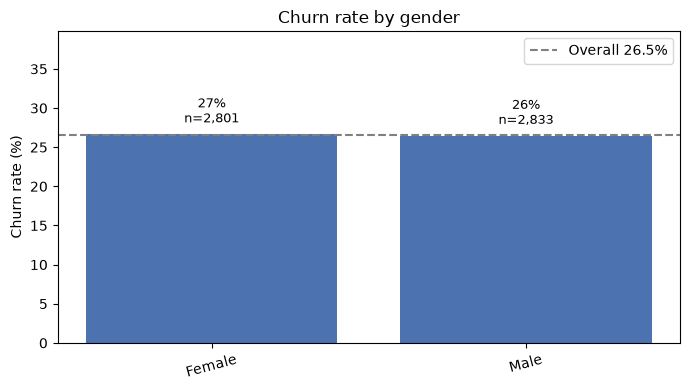

           n  rate_pct
gender                
Female  2801      26.6
Male    2833      26.4


In [24]:
# SeniorCitizen: 1 = senior. Gender is included as a check of whether it matters at all.
for col in ["SeniorCitizen", "Partner", "Dependents", "gender"]:
    churn_rate_bar(train_eda, col, f"Churn rate by {col}", filename=f"eda_9_{col}.png")

### Hypotheses (written before modelling, all tested in section 7)
Each is "once the other factors are accounted for" (associations, not causes).
- **H1** Month-to-month customers have higher risk than contract customers, even at the same tenure.
- **H2** Risk is highest in the first months and falls with tenure, even within the same contract.
- **H3** Fiber customers have higher risk than DSL, beyond what their higher price explains.
- **H4** Online security / tech support lower risk.
- **H5** Electronic-check payers have higher risk than automatic payers.
- **H6** Demographic gaps shrink once account variables are included; gender has no effect.
- **H7** A price change adds little signal.
- **H8** The model reaches more churners than the simple rule "month-to-month and tenure ≤ 6" at the same list size (test set).

H1, H2, H3 and H8 are the headline hypotheses; H4–H7 are supporting checks.

## 4. Preprocessing
**Principle:** best out-of-sample prediction, as in production. Each model gets the preprocessing that suits it; the comparison is fair because all models use the same folds, test set and metrics. Fixed rules go in `clean_features`; anything learned from data (scaling, encoding) sits inside a pipeline fitted on training folds only.

**Decisions** (the numbers are referred to in the code comments):
- **4.1** Blank `TotalCharges` → 0. These are new customers who have not yet been billed, and tenure × `MonthlyCharges` also gives 0. They are not dropped: they are real customers who need a score.
- **4.2** `TotalCharges` is left out of logistic regression (near-perfect collinearity); for trees, CV decides.
- **4.3** "No internet/phone service" → "No". The not-applicable information stays in `InternetService` / `PhoneService`.
- **4.4** One-hot encoding. Logistic regression drops one reference level (Month-to-month, DSL, Bank transfer, "No"); trees keep all levels.
- **4.5** `MonthlyCharges` is left out of logistic regression after the VIF check below. It is almost fully the sum of the services a customer has, so it adds no information and makes coefficients unstable. It is still used to value customers in section 8, and trees keep it.
- **4.6** `gender` is excluded from the model (no signal, protected attribute) but kept for the fairness check. `SeniorCitizen` follows the same rule: it is kept only if it adds measurable value (tested in section 6).
- **4.7** Tenure form for logistic regression: linear, or "both" (tenure + log tenure). The shape check is below; the final choice is made in section 6.
- **4.8** Scaling for logistic regression only.
- **4.9** No extra feature engineering. There are only 5,634 training rows, new features would mostly re-express existing information, and it keeps the H8 comparison clean. The price-change ratio is created only to test H7.

### Tenure shape check (decision 4.7)
How should tenure enter the logistic regression (trees find the shape themselves)? One-variable CV comparison of linear, log, bands and "both" (tenure + log tenure).
**Result:** "both" best, but within fold-to-fold noise; bands worst (they blur the month-1 spike). **Decision:** carry linear and "both" forward and compare them in the full model (section 6).

linear  CV log-loss: 0.5134  (fold sd 0.0041)
log1p   CV log-loss: 0.5142  (fold sd 0.0075)


bands   CV log-loss: 0.5165  (fold sd 0.0057)
both    CV log-loss: 0.5116  (fold sd 0.0050)


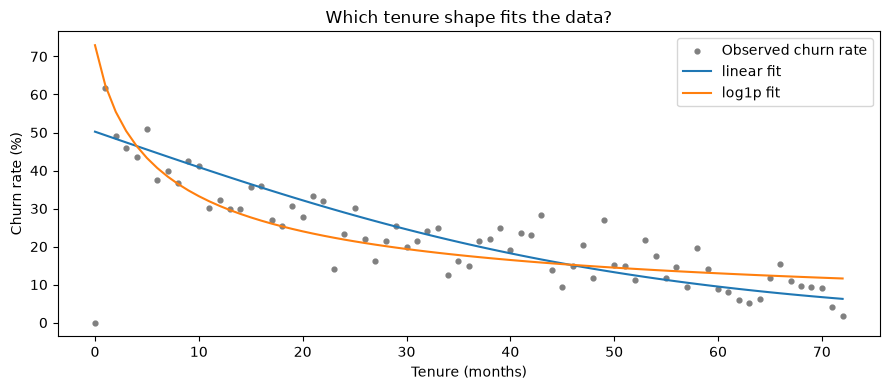

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Same 5 folds for every option, so the comparison is fair
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_train = train_df["Churn"]

# Four ways to represent tenure (bands use fixed cut points, so nothing is learned from the data)
tenure_forms = {
    "linear": train_df[["tenure"]],
    "log1p":  np.log1p(train_df[["tenure"]]),
    "bands":  pd.get_dummies(pd.cut(train_df["tenure"], bins=tenure_bins, labels=tenure_labels),
                             drop_first=True),
    # both: lets the model capture a steep early drop AND a continued decline later
    "both":   pd.concat([train_df[["tenure"]],
                         np.log1p(train_df[["tenure"]]).rename(columns={"tenure": "log_tenure"})],
                        axis=1),
}

# Log-loss: lower is better. The fold sd shows how much scores vary between folds;
# if the gaps between options are smaller than that, they are effectively tied.
for name, X in tenure_forms.items():
    scores = -cross_val_score(LogisticRegression(), X, y_train, cv=cv, scoring="neg_log_loss")
    print(f"{name:7s} CV log-loss: {scores.mean():.4f}  (fold sd {scores.std():.4f})")

# Visual check: observed churn rate per tenure month vs the fitted curves
rate_by_month = train_df.groupby("tenure")["Churn"].mean()
months = np.arange(0, 73).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(rate_by_month.index, rate_by_month.values * 100, s=12, color="grey",
           label="Observed churn rate")
for name, transform in [("linear", lambda t: t), ("log1p", np.log1p)]:
    model = LogisticRegression().fit(transform(train_df[["tenure"]].values), y_train)
    ax.plot(months, model.predict_proba(transform(months))[:, 1] * 100, label=f"{name} fit")
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate (%)")
ax.set_title("Which tenure shape fits the data?")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "step4_tenure_shape_check.png", dpi=200)
plt.show()

In [26]:
INTERNET_ADDONS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies"]

def clean_features(data):
    """Fixed, row-by-row rules. Nothing is learned from the data, so this is leakage-free
    and gives the same result for train, test, or next month's customers."""
    out = data.copy()

    # 4.1: blank TotalCharges = brand-new customers not yet billed, so 0 is the true value
    out["TotalCharges"] = out["TotalCharges"].fillna(0)

    # 4.3: "No internet/phone service" -> "No". The "not applicable" info is still in
    # InternetService / PhoneService, so nothing is lost, and the duplicate columns disappear
    for col in INTERNET_ADDONS:
        out[col] = out[col].replace("No internet service", "No")
    out["MultipleLines"] = out["MultipleLines"].replace("No phone service", "No")

    # 4.7: log tenure, available for the "both" option in logistic regression
    out["log_tenure"] = np.log1p(out["tenure"])

    # H7 test only: price-change ratio (1.0 for tenure 0, where no history exists)
    expected_total = out["tenure"] * out["MonthlyCharges"]
    out["charge_ratio"] = np.where(out["tenure"] > 0,
                                   out["TotalCharges"] / expected_total.where(expected_total > 0),
                                   1.0)
    return out

train_clean = clean_features(train_df)
test_clean = clean_features(test_df)

print("Missing values after cleaning:", train_clean.isna().sum().sum(), "(train),",
      test_clean.isna().sum().sum(), "(test)")
print("Add-on levels now:", sorted(train_clean["OnlineSecurity"].unique()),
      "| MultipleLines:", sorted(train_clean["MultipleLines"].unique()))

Missing values after cleaning: 0 (train), 0 (test)
Add-on levels now: ['No', 'Yes'] | MultipleLines: ['No', 'Yes']


In [27]:
# Which columns play which role. gender is deliberately NOT a feature (4.6),
# but stays in the data for the fairness audit in section 8.
CATEGORICAL = ["Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService",
               *INTERNET_ADDONS, "Contract", "PaperlessBilling", "PaymentMethod"]
BINARY_NUMERIC = ["SeniorCitizen"]   # already 0/1
AUDIT_ONLY = ["gender"]
TARGET = "Churn"

y_train = train_clean[TARGET]
y_test = test_clean[TARGET]

In [28]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set by the VIF check below (decision 4.5). Until then, MonthlyCharges is included by default.
LR_INCLUDE_MONTHLY = True

def make_lr_preprocessor(tenure_form="linear", include_senior=True, include_monthly=None):
    """Logistic regression: scaled numbers, one reference level dropped per category (4.4, 4.8).
    TotalCharges is left out on purpose (4.2: near-perfect collinearity)."""
    # include_monthly=None -> follow the VIF decision (LR_INCLUDE_MONTHLY)
    if include_monthly is None:
        include_monthly = LR_INCLUDE_MONTHLY
    numeric = ["tenure"] + (["MonthlyCharges"] if include_monthly else []) + (["log_tenure"] if tenure_form == "both" else [])
    passthrough = BINARY_NUMERIC if include_senior else []
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        # drop="first" -> alphabetical references: Month-to-month, DSL, Bank transfer, "No"
        # handle_unknown="ignore" -> a new category in future data won't crash the model
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORICAL),
        ("bin", "passthrough", passthrough),   # 0/1 stays 0/1, so it's easy to read
    ], remainder="drop", verbose_feature_names_out=False)   # remainder="drop": gender etc. never get in

def make_tree_preprocessor(include_total_charges=False, include_senior=True):
    """Trees: no scaling needed; all category levels kept (only yes/no columns lose one).
    TotalCharges is optional, so cross-validation can decide (4.2)."""
    numeric = ["tenure", "MonthlyCharges"] + (["TotalCharges"] if include_total_charges else [])
    numeric += BINARY_NUMERIC if include_senior else []
    return ColumnTransformer([
        ("num", "passthrough", numeric),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), CATEGORICAL),
    ], remainder="drop", verbose_feature_names_out=False)

In [29]:
# Sanity check only: fit each preprocessor on TRAIN, then apply to TEST.
# In sections 5 and 6 they are fitted inside cross-validation, never on all data at once.
checks = {"LR (linear tenure)": make_lr_preprocessor("linear"),
          "LR (both tenure)":   make_lr_preprocessor("both"),
          "Trees":              make_tree_preprocessor()}

for name, prep in checks.items():
    X_tr = prep.fit_transform(train_clean)
    X_te = prep.transform(test_clean)
    print(f"\n{name}: {X_tr.shape[1]} features | train {X_tr.shape} | test {X_te.shape}")
    print(list(prep.get_feature_names_out()))

# Confirm nothing forbidden slipped into the model inputs
lr_names = make_lr_preprocessor().fit(train_clean).get_feature_names_out()
forbidden = [c for c in ["gender", "Churn", "TotalCharges"] if c in lr_names]
print("\nForbidden columns in LR features:", forbidden if forbidden else "none")

print("\nPrice-change ratio (for the H7 test):")
print(train_clean["charge_ratio"].describe().round(3))


LR (linear tenure): 21 features | train (5634, 21) | test (1409, 21)
['tenure', 'MonthlyCharges', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'SeniorCitizen']

LR (both tenure): 22 features | train (5634, 22) | test (1409, 22)
['tenure', 'MonthlyCharges', 'log_tenure', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (


Trees: 24 features | train (5634, 24) | test (1409, 24)
['tenure', 'MonthlyCharges', 'SeniorCitizen', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_DSL', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_Month-to-month', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Bank transfer (automatic)', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

Forbidden columns in LR features: none

Price-change ratio (for the H7 test):
count    5634.000
mean        1.001
std         0.051
min         0.689
25%         0.980
50%         1.000
75%         1.019
max         1.531
Name: charge_ratio, dtype: float64


### Multicollinearity check (VIF) before modelling
Logistic regression coefficients become unstable when one feature can be predicted from the others. The **Variance Inflation Factor (VIF)** measures this per feature: VIF = 1 / (1 − R²), where R² comes from predicting that feature from all other features. Rule of thumb: VIF > 5 worth a look, VIF > 10 serious.
Pairwise correlations can miss this when a feature is explained by a *combination* of others (e.g. a price that is the sum of the services), so VIF is checked on the full logistic-regression design matrix (training data, linear tenure; tenure + log tenure are deliberately related and read together, so they are not judged by VIF).

In [30]:
# VIF check on the logistic-regression features (training data only)
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

def vif_table(prep, data):
    """VIF for every feature produced by a preprocessor (fitted on training data)."""
    X = pd.DataFrame(prep.fit_transform(data), columns=prep.get_feature_names_out(), index=data.index)
    X = sm.add_constant(X)   # VIF needs an intercept to be computed correctly
    vifs = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
    return pd.Series(vifs, index=X.columns).drop("const")

vif = pd.DataFrame({
    "with MonthlyCharges": vif_table(make_lr_preprocessor("linear", include_senior=False, include_monthly=True), train_clean),
    "without MonthlyCharges": vif_table(make_lr_preprocessor("linear", include_senior=False, include_monthly=False), train_clean),
}).sort_values("with MonthlyCharges", ascending=False)
print(vif.round(1).to_string())
print("\nFeatures with VIF > 10 (with MonthlyCharges):", list(vif.index[vif["with MonthlyCharges"] > 10]))
print("Max VIF without MonthlyCharges:", round(vif["without MonthlyCharges"].max(), 1))

# How much of MonthlyCharges do the services explain? (R² of price on the service columns)
svc = make_lr_preprocessor("linear", include_senior=False, include_monthly=False).fit(train_clean)
X_svc = pd.DataFrame(svc.transform(train_clean), columns=svc.get_feature_names_out(), index=train_clean.index)
service_cols = ["PhoneService_Yes", "MultipleLines_Yes", "InternetService_Fiber optic", "InternetService_No",
                *[f"{c}_Yes" for c in INTERNET_ADDONS]]
from sklearn.linear_model import LinearRegression
r2_price = LinearRegression().fit(X_svc[service_cols], train_clean["MonthlyCharges"]).score(
    X_svc[service_cols], train_clean["MonthlyCharges"])
print(f"Share of MonthlyCharges explained by the services alone: R² = {r2_price:.4f}")

# DECISION 4.5: MonthlyCharges out of logistic regression from here on.
# It is still used to value customers in euros (section 8); trees keep it (collinearity doesn't hurt them).
LR_INCLUDE_MONTHLY = False
print("LR_INCLUDE_MONTHLY =", LR_INCLUDE_MONTHLY)

                                       with MonthlyCharges  without MonthlyCharges
MonthlyCharges                                       860.0                     NaN
InternetService_Fiber optic                          147.7                     2.0
InternetService_No                                   103.0                     2.7
PhoneService_Yes                                      35.3                     1.4
StreamingTV_Yes                                       24.0                     1.6
StreamingMovies_Yes                                   24.0                     1.6
MultipleLines_Yes                                      7.2                     1.4
DeviceProtection_Yes                                   6.9                     1.5
OnlineBackup_Yes                                       6.7                     1.4
TechSupport_Yes                                        6.5                     1.5
OnlineSecurity_Yes                                     6.3                     1.4
tenu

## 5. Model comparison
**Line-up**
- Dummy model: sanity check.
- Business rule "month-to-month & tenure ≤ 6": the floor, committed before modelling.
- **Logistic regression**: main model, interpretable, without `MonthlyCharges`.
- **XGBoost**: flexible challenger.

A decision tree (unstable) and a random forest (same family as XGBoost) were considered but not built.

The top-20% contact budget used in the metrics is **illustrative**, not a known capacity. The nested-CV cell below takes a few minutes.

### Validation choices and alternatives considered

| Decision | Chosen | Alternatives considered | Why this choice |
|---|---|---|---|
| **Validation scheme** | Nested CV: 5 outer folds score, 5 inner folds tune; test set (20%) used once for the final model | Single train/validation/test split; plain k-fold CV with tuning and scoring on the same folds; repeated CV; time-based split | A single validation split (~1,100 customers) is too noisy with 7,043 rows; tuning and scoring on the same folds is optimistic; repeated CV adds little here (robustness seeds show results move by ≤ 0.005); a time-based split is impossible (no dates) |
| **Model-selection metric** | PR-AUC | Accuracy; ROC-AUC; F1 or recall at the 0.5 threshold; log-loss; a business metric (churners reached in the top 20%) | Accuracy is misleading (73.5% by predicting "nobody leaves"); PR-AUC focuses on how well churners are ranked at the top; F1/recall depend on an arbitrary threshold; the top-20% metric is noisy at a single cut-off and depends on an assumed budget. ROC-AUC, log-loss and top-20% are still **reported** |
| **Class imbalance (26.5% churn)** | No reweighting or resampling | `class_weight="balanced"`; SMOTE / oversampling; undersampling | Imbalance is moderate; ranking metrics barely change with reweighting; reweighting and SMOTE distort predicted probabilities, which the € calculation needs; SMOTE creates synthetic customers and leaks if applied before the split; undersampling throws away data. Imbalance is handled where it matters: the metric (PR-AUC) and the list size / threshold (section 8) |
| **Tuning scope** | Light: logistic regression C ∈ {0.01, 0.1, 1, 10} (+ tenure form); XGBoost depth 2–4, learning rate 0.03/0.1, min child weight 1/5, with/without TotalCharges | No tuning (defaults); large random or Bayesian search; L1 / elastic-net logistic regression | Gains from heavy tuning are tiny on this dataset (models tie within noise) and heavy search risks overfitting the CV folds; L1 feature selection isn't needed because interpretation uses a separate inference model |
| **Choosing C** | Best inner-CV score | One-standard-error rule (would give C = 0.01) | Flat curve; ample data per feature; strong shrinkage would distort probabilities (see check in section 6) |
| **Final evaluation** | Test set used once per locked model; CV vs test shown side by side; robustness seeds fixed in advance | Choosing between models on the test set | Choosing on the test set would make its score optimistic; the test only measures the chosen model |

**In short**
- *Why PR-AUC rather than ROC-AUC?* The business only acts on the top of the list, and PR-AUC rewards getting that part right. ROC-AUC is reported too, and both lead to the same choice (no-skill baseline: PR-AUC 0.265 vs ROC-AUC 0.5).
- *Why no reweighting or resampling?* Customers are ranked, not classified at 0.5. Reweighting doesn't improve the ranking, but it inflates the probabilities the € calculation needs (checked in section 6).
- *Why light tuning?* Performance was flat across the grid: different C values and XGBoost depths all landed within noise. A larger search would mostly fit noise in the folds.

In [31]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss
from xgboost import XGBClassifier

TOP_SHARE = 0.20   # contact budget for the headline metric: the riskiest 20% of customers

RULE_MAX_TENURE = 6   # pre-committed with the hypotheses (H8), before modelling

def business_rule(data, max_tenure=RULE_MAX_TENURE):
    """Floor: a rule anyone could run in Excel, committed before modelling (H8).
    Learns nothing, so it needs no fitting."""
    return ((data["Contract"] == "Month-to-month") & (data["tenure"] <= max_tenure)).astype(int)

def describe_settings(search):
    """Readable summary of what the inner CV picked (empty for the dummy, which has no search)."""
    if not hasattr(search, "best_params_"):
        return ""
    settings = {k.replace("model__", ""): v for k, v in search.best_params_.items() if k != "prep"}
    numeric = search.best_params_["prep"].transformers[0][2]   # the "num" columns used
    if isinstance(search.best_estimator_["model"], XGBClassifier):
        settings["TotalCharges"] = "TotalCharges" in numeric      # tree option (4.2)
    else:
        settings["log_tenure"] = "log_tenure" in numeric          # LR tenure option (4.7)
    return settings

def churners_caught(y_true, score, n_contacts):
    """How many real churners are among the n customers with the highest score."""
    top = np.argsort(-np.asarray(score), kind="stable")[:n_contacts]
    return int(np.asarray(y_true)[top].sum())

In [32]:
# Each search tries a few settings with an INNER 5-fold CV and keeps the best.
# The preprocessing choice is part of the search, so CV decides it, not us.
candidates = {
    # Sanity check only: predicts the average churn rate for everyone
    "Dummy (no skill)": Pipeline([("prep", make_lr_preprocessor()),
                                  ("model", DummyClassifier(strategy="prior"))]),
    "Logistic regression": GridSearchCV(
        Pipeline([("prep", make_lr_preprocessor()),
                  ("model", LogisticRegression(max_iter=2000))]),
        {"prep": [make_lr_preprocessor("linear"), make_lr_preprocessor("both")],
         "model__C": [0.01, 0.1, 1, 10]},             # C: smaller = simpler, more cautious model
        scoring="average_precision", cv=5, n_jobs=-1),
    "XGBoost": GridSearchCV(
        Pipeline([("prep", make_tree_preprocessor()),
                  ("model", XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                                          tree_method="hist", eval_metric="logloss",
                                          random_state=RANDOM_STATE, n_jobs=1))]),
        {"prep": [make_tree_preprocessor(False), make_tree_preprocessor(True)],
         "model__max_depth": [2, 3, 4],               # light tuning on purpose
         "model__learning_rate": [0.03, 0.1],
         "model__min_child_weight": [1, 5]},
        scoring="average_precision", cv=5, n_jobs=-1),
}

In [33]:
# OUTER folds score each model on customers its tuning never saw
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_train = train_clean.drop(columns=TARGET)

rows, oof = [], {name: pd.Series(np.nan, index=X_train.index) for name in candidates}
oof["Business rule"] = business_rule(X_train)          # the rule's "score" is simply 0/1

for fold, (tr, va) in enumerate(outer_cv.split(X_train, y_train), start=1):
    X_tr, X_va = X_train.iloc[tr], X_train.iloc[va]
    y_tr, y_va = y_train.iloc[tr], y_train.iloc[va]

    rule_flag = business_rule(X_va)
    n_rule = int(rule_flag.sum())                       # list size the rule produces
    n_top = int(round(TOP_SHARE * len(y_va)))

    for name, search in candidates.items():
        search.fit(X_tr, y_tr)
        p = search.predict_proba(X_va)[:, 1]
        oof[name].iloc[va] = p                          # out-of-fold scores, for the gains chart
        rows.append({
            "model": name, "fold": fold,
            "ROC-AUC": roc_auc_score(y_va, p),
            "PR-AUC": average_precision_score(y_va, p),
            "log-loss": log_loss(y_va, p),
            f"% churners caught, top {TOP_SHARE:.0%}": churners_caught(y_va, p, n_top) / y_va.sum(),
            # same list size as the rule -> fair head-to-head
            "caught at rule's list size": churners_caught(y_va, p, n_rule),
            "best settings": describe_settings(search),
        })
    rows.append({"model": "Business rule", "fold": fold,
                 "caught at rule's list size": int(y_va[rule_flag == 1].sum()),
                 "list size": n_rule})

results = pd.DataFrame(rows)
print("Done.")

Done.


In [34]:
metric_cols = ["ROC-AUC", "PR-AUC", "log-loss", f"% churners caught, top {TOP_SHARE:.0%}"]
summary = results.groupby("model", sort=False)[metric_cols].agg(["mean", "std"]).round(3)
print("Mean and spread over the 5 outer folds:\n")
print(summary.drop(index="Business rule").to_string())

h2h = results.groupby("model", sort=False)["caught at rule's list size"].sum()
n_rule_total = int(results["list size"].sum())
print(f"\nHead-to-head at the rule's list size ({n_rule_total:,} customers = "
      f"{n_rule_total / len(y_train):.0%} of all; {int(y_train.sum()):,} churners in total):")
print(h2h.drop(index="Dummy (no skill)").to_string())

print("\nSettings chosen by the inner CV in each outer fold (stable = trustworthy):")
for name in ["Logistic regression", "XGBoost"]:
    print(f"\n{name}:")
    for s in results.loc[results["model"] == name, "best settings"]:
        print("  ", s)

Mean and spread over the 5 outer folds:

                    ROC-AUC        PR-AUC        log-loss        % churners caught, top 20%       
                       mean    std   mean    std     mean    std                       mean    std
model                                                                                             
Dummy (no skill)      0.500  0.000  0.265  0.000    0.579  0.000                      0.197  0.007
Logistic regression   0.850  0.013  0.673  0.017    0.410  0.013                      0.514  0.023
XGBoost               0.849  0.013  0.668  0.022    0.412  0.014                      0.511  0.024

Head-to-head at the rule's list size (1,122 customers = 20% of all; 1,495 churners in total):
model
Logistic regression    763
XGBoost                761
Business rule          610

Settings chosen by the inner CV in each outer fold (stable = trustworthy):

Logistic regression:
   {'C': 1, 'log_tenure': True}
   {'C': 10, 'log_tenure': True}
   {'C': 1, 'log_ten

### Gains curve
Share of all churners reached when contacting customers from highest to lowest risk, for every possible budget; the rule appears as a single point.

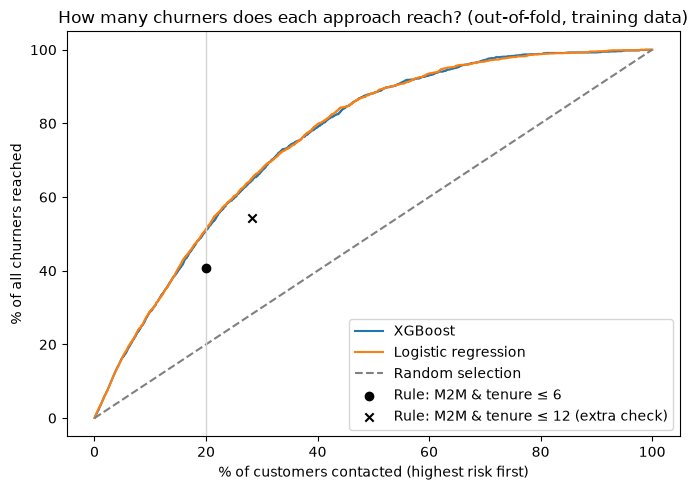

In [35]:
def gains(y, score):
    """% of churners reached when contacting customers from highest to lowest score."""
    order = np.argsort(-np.asarray(score), kind="stable")
    caught = np.cumsum(np.asarray(y)[order]) / np.sum(y)
    contacted = np.arange(1, len(y) + 1) / len(y)
    return contacted * 100, caught * 100

fig, ax = plt.subplots(figsize=(7, 5))
for name in ["XGBoost", "Logistic regression"]:
    ax.plot(*gains(y_train, oof[name]), label=name)
ax.plot([0, 100], [0, 100], "--", color="grey", label="Random selection")

# Official rule (tenure <= 6, pre-committed) as a dot; tenure <= 12 as a cross (extra check)
for max_t, marker in [(RULE_MAX_TENURE, "o"), (12, "x")]:
    flag = business_rule(X_train, max_t)
    ax.scatter([flag.mean() * 100], [y_train[flag == 1].sum() / y_train.sum() * 100],
               color="black", marker=marker, zorder=5,
               label=f"Rule: M2M & tenure ≤ {max_t}" + (" (extra check)" if max_t == 12 else ""))

ax.axvline(TOP_SHARE * 100, color="lightgrey", linewidth=1)
ax.set_xlabel("% of customers contacted (highest risk first)")
ax.set_ylabel("% of all churners reached")
ax.set_title("How many churners does each approach reach? (out-of-fold, training data)")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(FIG_DIR / "step5_gains_curve.png", dpi=200)
plt.show()

## 6. Final model
**Result of section 5:** logistic regression and XGBoost are tied. The gaps are smaller than the fold-to-fold spread, and XGBoost picked shallow trees, which means mostly additive effects. Both beat the rule. **Logistic regression was chosen before looking at the test set** (equal performance, explainable).

### 6.1 Specification checks: tenure shape and SeniorCitizen
Same outer folds, training data only, C = 1. Four variants: tenure linear vs "both", with vs without `SeniorCitizen`.
- **Tenure:** "both" is better on PR-AUC in all 5 folds and on ROC-AUC in 4 of 5 (paired comparison below), and it matches H2's steep early drop. **Kept.**
- **SeniorCitizen:** removing it costs no ROC-AUC, and the PR-AUC difference is within noise. **Dropped** from the model (decision 4.6) and kept for the fairness check.

In [36]:
# Specification checks (decisions 4.7 and 4.6): training data only, same outer folds.
from sklearn.model_selection import cross_validate

def top_share_caught(estimator, X, y):
    """Business metric: share of all churners reached in the top 20% (illustrative budget)."""
    p = estimator.predict_proba(X)[:, 1]
    return churners_caught(y, p, int(round(TOP_SHARE * len(y)))) / np.sum(y)

variants = {
    "both + senior":     ("both", True),
    "linear + senior":   ("linear", True),
    "both, no senior":   ("both", False),
    "linear, no senior": ("linear", False),
}
BUSINESS = f"caught top {TOP_SHARE:.0%}"
check_scores = {}
for name, (form, senior) in variants.items():
    pipe = Pipeline([("prep", make_lr_preprocessor(form, include_senior=senior)),
                     ("model", LogisticRegression(C=1, max_iter=2000))])   # C=1 = the chosen setting
    s = cross_validate(pipe, X_train, y_train, cv=outer_cv,
                       scoring={"ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
                                BUSINESS: top_share_caught})
    check_scores[name] = pd.DataFrame({k.replace("test_", ""): v
                                       for k, v in s.items() if k.startswith("test_")})

table = pd.concat({n: d.agg(["mean", "std"]).T for n, d in check_scores.items()}, axis=0).unstack()
print(table.round(4).to_string())

                     mean                            std                       
                  ROC-AUC  PR-AUC caught top 20% ROC-AUC  PR-AUC caught top 20%
both + senior      0.8505  0.6733         0.5137  0.0130  0.0175         0.0232
linear + senior    0.8451  0.6602         0.5064  0.0135  0.0201         0.0207
both, no senior    0.8504  0.6739         0.5124  0.0135  0.0188         0.0216
linear, no senior  0.8450  0.6599         0.5070  0.0139  0.0215         0.0215


In [37]:
# Fold-by-fold comparison: both versions are scored on the SAME folds, so compare them pairwise
paired = pd.DataFrame({m: check_scores["both, no senior"][m] - check_scores["linear, no senior"][m]
                       for m in ["ROC-AUC", "PR-AUC", BUSINESS]})
paired.index = [f"fold {i}" for i in range(1, 6)]
print("'both' minus 'linear' (no SeniorCitizen), per fold:")
print(paired.round(4).to_string())
print("\nFolds where 'both' is better:", (paired > 0).sum().to_dict())

'both' minus 'linear' (no SeniorCitizen), per fold:
        ROC-AUC  PR-AUC  caught top 20%
fold 1  -0.0017  0.0100         -0.0134
fold 2   0.0081  0.0217          0.0134
fold 3   0.0065  0.0112          0.0201
fold 4   0.0020  0.0034         -0.0033
fold 5   0.0124  0.0234          0.0100

Folds where 'both' is better: {'ROC-AUC': 4, 'PR-AUC': 5, 'caught top 20%': 3}


### SeniorCitizen check on PR-AUC (same 5 stratified folds)
The SeniorCitizen rule was written with ROC-AUC; the same comparison on PR-AUC (the model-selection metric), fold by fold.

In [38]:
# SeniorCitizen check on PR-AUC: same 5 stratified outer folds, read from the check above (no refitting)
pr_with = check_scores["both + senior"]["PR-AUC"]
pr_without = check_scores["both, no senior"]["PR-AUC"]
diff = pr_with - pr_without                      # positive = SeniorCitizen helps
print(pd.DataFrame({"with SeniorCitizen": pr_with.values, "without SeniorCitizen": pr_without.values,
                    "difference": diff.values}, index=[f"fold {i}" for i in range(1, 6)]).round(4).to_string())
print(f"\nMean difference: {diff.mean():+.4f}")
print(f"Fold sd of PR-AUC (with SeniorCitizen): {pr_with.std():.4f}")
print(f"Sd of the fold-by-fold difference: {diff.std():.4f}")
print("Folds where SeniorCitizen helps:", int((diff > 0).sum()), "of 5")

        with SeniorCitizen  without SeniorCitizen  difference
fold 1              0.6549                 0.6536      0.0014
fold 2              0.6553                 0.6550      0.0003
fold 3              0.6943                 0.6958     -0.0015
fold 4              0.6801                 0.6794      0.0007
fold 5              0.6818                 0.6856     -0.0038

Mean difference: -0.0006
Fold sd of PR-AUC (with SeniorCitizen): 0.0175
Sd of the fold-by-fold difference: 0.0021
Folds where SeniorCitizen helps: 3 of 5


### 6.2 Final model and test-set evaluation
**Locked:** logistic regression, tenure "both" (tenure + log tenure), `SeniorCitizen` dropped (6.1), `MonthlyCharges` excluded (decision 4.5). CV chooses C. One model serves both prediction and interpretation. Every decision was made on training data; the test set only measures this model.

In [39]:
# FINAL MODEL. All choices made on training-data CV only:
# - logistic regression (tied with XGBoost in section 5; simpler and explainable)
# - tenure as "both" (tenure + log tenure): better overall ranking in all 5 folds, matches H2's early drop
# - SeniorCitizen dropped: removing it costs no ROC-AUC; kept aside for the fairness check
# - MonthlyCharges dropped: services explain it almost fully (R² ≈ 0.999), it adds no
#   predictive value (CV PR-AUC unchanged), and removing it makes this model's coefficients readable
FINAL_NAME = "Logistic regression"
FINAL_TENURE, FINAL_SENIOR, FINAL_MONTHLY = "both", False, False

final_search = GridSearchCV(
    Pipeline([("prep", make_lr_preprocessor(FINAL_TENURE, include_senior=FINAL_SENIOR, include_monthly=FINAL_MONTHLY)),
              ("model", LogisticRegression(max_iter=2000))]),
    {"model__C": [0.01, 0.1, 1, 10]}, scoring="average_precision", cv=5, n_jobs=-1)

# Nested CV of this exact setup (inner CV picks C, outer folds score it) = the "CV" column for the test comparison
final_cv = cross_validate(final_search, X_train, y_train, cv=outer_cv,
                          scoring={"ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
                                   "log-loss": "neg_log_loss",
                                   f"% churners caught, top {TOP_SHARE:.0%}": top_share_caught})
cv_means = pd.Series({k.replace("test_", ""): (-v.mean() if "log-loss" in k else v.mean())
                      for k, v in final_cv.items() if k.startswith("test_")})

final_search.fit(X_train, y_train)            # inner CV on ALL training data picks the final C
final_model = final_search.best_estimator_    # refitted on all 5,634 training customers
print("Final settings: C =", final_search.best_params_["model__C"],
      f"| tenure = {FINAL_TENURE} | SeniorCitizen = {FINAL_SENIOR} | MonthlyCharges = {FINAL_MONTHLY}")
print(cv_means.round(3).to_string())

Final settings: C = 10 | tenure = both | SeniorCitizen = False | MonthlyCharges = False
ROC-AUC                       0.850
PR-AUC                        0.674
log-loss                      0.411
% churners caught, top 20%    0.512


In [40]:
# Evaluation of the final model on the test set (used once)
X_test = test_clean.drop(columns=TARGET)
p_test = final_model.predict_proba(X_test)[:, 1]
n_top = int(round(TOP_SHARE * len(y_test)))
caught_top = churners_caught(y_test, p_test, n_top)

test_metrics = {
    "ROC-AUC": roc_auc_score(y_test, p_test),
    "PR-AUC": average_precision_score(y_test, p_test),
    "log-loss": log_loss(y_test, p_test),
    f"% churners caught, top {TOP_SHARE:.0%}": caught_top / y_test.sum(),
}
# CV vs test side by side: similar numbers = no overfitting, CV was trustworthy
print(pd.DataFrame({"CV (train)": cv_means, "Test": pd.Series(test_metrics)}).round(3).to_string())

rule_test = business_rule(X_test)
n_rule_test = int(rule_test.sum())
print(f"\nTop {TOP_SHARE:.0%} list on test: {n_top} customers, {caught_top} real churners "
      f"({caught_top / n_top:.0%} hit rate vs {y_test.mean():.0%} if picked at random)")
print(f"Same list size as the rule ({n_rule_test} customers): model "
      f"{churners_caught(y_test, p_test, n_rule_test)} churners vs rule "
      f"{int(y_test[rule_test == 1].sum())} (of {int(y_test.sum())} in test)")

                            CV (train)   Test
ROC-AUC                          0.850  0.847
PR-AUC                           0.674  0.665
log-loss                         0.411  0.413
% churners caught, top 20%       0.512  0.516

Top 20% list on test: 282 customers, 193 real churners (68% hit rate vs 27% if picked at random)
Same list size as the rule (291 customers): model 194 churners vs rule 170 (of 374 in test)


In [41]:
# Same model and settings, different CV fold seeds (fixed in section 1, before any results).
# If the scores barely move, the CV result was not the luck of one particular split.
seed_rows = []
for seed in ROBUSTNESS_SEEDS:
    cv_seed = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    s = cross_validate(clone(final_model), X_train, y_train, cv=cv_seed,
                       scoring={"ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
                                "log-loss": "neg_log_loss"})
    seed_rows.append({"seed": seed, "ROC-AUC": s["test_ROC-AUC"].mean(),
                      "PR-AUC": s["test_PR-AUC"].mean(), "log-loss": -s["test_log-loss"].mean()})
seed_df = pd.DataFrame(seed_rows).set_index("seed")
print(seed_df.round(3).to_string())
print("\nRange across seeds:", (seed_df.max() - seed_df.min()).round(3).to_dict())

      ROC-AUC  PR-AUC  log-loss
seed                           
0       0.850   0.674     0.411
7       0.850   0.674     0.410
99      0.851   0.672     0.410
123     0.850   0.677     0.411
2026    0.851   0.673     0.410

Range across seeds: {'ROC-AUC': 0.0, 'PR-AUC': 0.005, 'log-loss': 0.001}


In [42]:
# Final model odds ratios. > 1 raises churn odds, < 1 lowers them; categories vs their reference;
# numbers (tenure, log_tenure) are scaled, so read them "per 1 standard deviation"
lr = final_model["model"]
coefs = pd.Series(lr.coef_[0], index=final_model["prep"].get_feature_names_out())
odds = pd.DataFrame({"coef": coefs, "odds_ratio": np.exp(coefs)}).sort_values("coef")
print(odds.round(2).to_string())

                                       coef  odds_ratio
Contract_Two year                     -1.71        0.18
InternetService_No                    -0.85        0.43
log_tenure                            -0.83        0.44
Contract_One year                     -0.75        0.47
PhoneService_Yes                      -0.54        0.58
OnlineSecurity_Yes                    -0.36        0.70
TechSupport_Yes                       -0.30        0.74
Dependents_Yes                        -0.23        0.79
OnlineBackup_Yes                      -0.15        0.86
PaymentMethod_Credit card (automatic) -0.02        0.98
PaymentMethod_Mailed check            -0.00        1.00
DeviceProtection_Yes                   0.03        1.03
tenure                                 0.04        1.05
Partner_Yes                            0.07        1.07
StreamingTV_Yes                        0.31        1.37
StreamingMovies_Yes                    0.32        1.37
PaymentMethod_Electronic check         0.35     

### 6.3 Check: how was C chosen? (information only)
C is chosen by inner CV on PR-AUC. If all values sit within one standard error of the best, the curve is flat; the one-standard-error rule would pick the simplest (smallest C). The best-scoring C is kept: ~75 churners per feature means little overfitting risk, and strong shrinkage would distort the probabilities used in section 8.

In [43]:
# Information only: what would the one-standard-error rule pick for C?
res = pd.DataFrame(final_search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]]
res["se"] = res["std_test_score"] / np.sqrt(final_search.n_splits_)
best = res.loc[res["mean_test_score"].idxmax()]
threshold = best["mean_test_score"] - best["se"]
c_1se = res.loc[res["mean_test_score"] >= threshold, "param_model__C"].astype(float).min()
print(res.round(4).to_string())
print(f"\nBest C: {best['param_model__C']} | 1-SE line: {threshold:.4f} | 1-SE rule would pick C = {c_1se}")
print(f"Churners per feature: {int(y_train.sum())} / {len(final_model['prep'].get_feature_names_out())}"
      f" = {y_train.sum() / len(final_model['prep'].get_feature_names_out()):.0f}")

   param_model__C  mean_test_score  std_test_score      se
0            0.01           0.6668          0.0281  0.0126
1            0.10           0.6731          0.0286  0.0128
2            1.00           0.6736          0.0278  0.0124
3           10.00           0.6737          0.0277  0.0124

Best C: 10.0 | 1-SE line: 0.6614 | 1-SE rule would pick C = 0.01
Churners per feature: 1495 / 20 = 75


### 6.4 Check: what would class reweighting change? (information only)
`class_weight="balanced"` leaves the ranking practically unchanged (rank correlation 1.00, 98% of the same customers in the top 20%). It does inflate the average predicted risk from 27% to 41%, which would overstate the € value in section 8, so the model is left unweighted.

In [44]:
from sklearn.model_selection import cross_val_predict
best_C = final_search.best_params_["model__C"]
cw_rows = []
for name, weights in [("no weights (final)", None), ("class_weight='balanced'", "balanced")]:
    pipe = Pipeline([("prep", make_lr_preprocessor(FINAL_TENURE, include_senior=FINAL_SENIOR, include_monthly=FINAL_MONTHLY)),
                     ("model", LogisticRegression(C=best_C, max_iter=2000, class_weight=weights))])
    s = cross_validate(pipe, X_train, y_train, cv=outer_cv,
                       scoring={"ROC-AUC": "roc_auc", "PR-AUC": "average_precision", "log-loss": "neg_log_loss"})
    p = cross_val_predict(pipe, X_train, y_train, cv=outer_cv, method="predict_proba")[:, 1]
    flagged = p >= 0.5
    cw_rows.append({"model": name, "ROC-AUC": s["test_ROC-AUC"].mean(), "PR-AUC": s["test_PR-AUC"].mean(),
                    "log-loss": -s["test_log-loss"].mean(), "avg predicted risk": p.mean(),
                    "share flagged at 0.5": flagged.mean(),
                    "recall at 0.5": (flagged & (y_train == 1).values).sum() / y_train.sum()})
print(pd.DataFrame(cw_rows).set_index("model").round(3).to_string())
print(f"\nActual churn rate (training): {y_train.mean():.3f}")

                         ROC-AUC  PR-AUC  log-loss  avg predicted risk  share flagged at 0.5  recall at 0.5
model                                                                                                      
no weights (final)          0.85   0.674     0.411               0.266                 0.215          0.544
class_weight='balanced'     0.85   0.672     0.483               0.411                 0.405          0.803

Actual churn rate (training): 0.265


In [45]:
# Direct check: how similar is the ORDER of customers with and without class weights?
from scipy.stats import spearmanr
pipe_w = Pipeline([("prep", make_lr_preprocessor(FINAL_TENURE, include_senior=FINAL_SENIOR, include_monthly=FINAL_MONTHLY)),
                   ("model", LogisticRegression(C=best_C, max_iter=2000, class_weight="balanced"))])
p_plain = cross_val_predict(clone(final_model), X_train, y_train, cv=outer_cv, method="predict_proba")[:, 1]
p_weighted = cross_val_predict(pipe_w, X_train, y_train, cv=outer_cv, method="predict_proba")[:, 1]
top = int(0.20 * len(p_plain))
overlap = len(set(np.argsort(-p_plain)[:top]) & set(np.argsort(-p_weighted)[:top])) / top
print(f"Rank correlation: {spearmanr(p_plain, p_weighted).correlation:.3f} | "
      f"same customers in the top 20%: {overlap:.0%}")

Rank correlation: 1.000 | same customers in the top 20%: 98%


## 7. Hypothesis tests (on the final model)
The final model's exact specification is refitted in statsmodels without regularization to get 95% confidence intervals (scikit-learn gives none); with C = 10 the odds ratios are almost identical. SeniorCitizen and gender are tested in separate audit fits (H6), never in the main table.
Reading: odds ratio > 1 = higher churn odds, < 1 = lower, holding the rest equal. Associations, not causes.

### H1–H5: odds ratios with 95% confidence intervals

In [46]:
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score
from sklearn.base import clone

# Same preprocessing as the final model (fitted on train), as a table with readable names
prep_final = final_model["prep"]
feat_names = prep_final.get_feature_names_out()
X_tr_all = pd.DataFrame(prep_final.transform(X_train), columns=feat_names, index=X_train.index)

# Check 1: is MonthlyCharges just the sum of the services a customer has?
service_cols = ["PhoneService_Yes", "MultipleLines_Yes", "InternetService_Fiber optic",
                "InternetService_No", *[f"{c}_Yes" for c in INTERNET_ADDONS]]
r2 = LinearRegression().fit(X_tr_all[service_cols], X_train["MonthlyCharges"]).score(
    X_tr_all[service_cols], X_train["MonthlyCharges"])
print(f"Share of MonthlyCharges explained by the services alone: R² = {r2:.4f}")

# Check 2: would adding MonthlyCharges back help? (the final model excludes it)
with_price = clone(final_model)
name, scaler, cols = with_price["prep"].transformers[0]
with_price["prep"].transformers[0] = (name, scaler, cols + ["MonthlyCharges"])
for label, model in [("without MonthlyCharges (final)", final_model), ("with MonthlyCharges", with_price)]:
    pr = cross_val_score(clone(model), X_train, y_train, cv=outer_cv, scoring="average_precision")
    print(f"CV PR-AUC {label:31s}: {pr.mean():.4f}")

# Inference model: the same features refitted in statsmodels (no regularisation) for
# 95% confidence intervals. Only used to read the hypotheses; the scoring model is unchanged.
X_tr_sm = sm.add_constant(X_tr_all.drop(columns="MonthlyCharges", errors="ignore"))
logit = sm.Logit(y_train, X_tr_sm).fit(disp=0)

ci = np.exp(logit.conf_int())
or_table = pd.DataFrame({"odds_ratio": np.exp(logit.params), "CI low": ci[0], "CI high": ci[1],
                         "p_value": logit.pvalues}).drop(index="const")
or_table["clear effect?"] = np.where(or_table["CI low"] > 1, "higher risk",
                             np.where(or_table["CI high"] < 1, "lower risk", "not clear"))
print()
print(or_table.sort_values("odds_ratio").round(3).to_string())

Share of MonthlyCharges explained by the services alone: R² = 0.9988
CV PR-AUC without MonthlyCharges (final) : 0.6739


CV PR-AUC with MonthlyCharges            : 0.6741

                                       odds_ratio  CI low  CI high  p_value clear effect?
Contract_Two year                           0.180   0.121    0.266    0.000    lower risk
InternetService_No                          0.429   0.315    0.586    0.000    lower risk
log_tenure                                  0.435   0.364    0.520    0.000    lower risk
Contract_One year                           0.472   0.371    0.601    0.000    lower risk
PhoneService_Yes                            0.587   0.441    0.781    0.000    lower risk
OnlineSecurity_Yes                          0.699   0.580    0.842    0.000    lower risk
TechSupport_Yes                             0.739   0.613    0.892    0.002    lower risk
Dependents_Yes                              0.793   0.652    0.964    0.020    lower risk
OnlineBackup_Yes                            0.863   0.729    1.021    0.086     not clear
PaymentMethod_Credit card (automatic)       0.980

### H6: demographics with and without controls, plus the gender audit (gender is never a model input)

In [47]:
# H6: do demographic gaps shrink once account variables are in the model?
# Separate fit: the final model's features + SeniorCitizen (an audit check, not part of the final model)
X_h6 = X_tr_sm.assign(SeniorCitizen=X_train["SeniorCitizen"].values)
demo = ["SeniorCitizen", "Partner_Yes", "Dependents_Yes"]
raw = sm.Logit(y_train, sm.add_constant(X_h6[demo])).fit(disp=0)        # demographics only
controlled = sm.Logit(y_train, X_h6).fit(disp=0)                         # + all account variables
print(pd.DataFrame({"raw OR": np.exp(raw.params[demo]),
                    "controlled OR": np.exp(controlled.params[demo])}).round(2).to_string())

# Gender: audit fit only (gender is never a feature of the final model)
X_gender = X_tr_sm.assign(Male=(X_train["gender"] == "Male").astype(int))
g = sm.Logit(y_train, X_gender).fit(disp=0)
g_ci = np.exp(g.conf_int().loc["Male"])
print(f"\nGender (male vs female), with controls: OR {np.exp(g.params['Male']):.2f} "
      f"(95% CI {g_ci[0]:.2f}–{g_ci[1]:.2f})")

                raw OR  controlled OR
SeniorCitizen     2.03           1.16
Partner_Yes       0.61           1.06
Dependents_Yes    0.56           0.82

Gender (male vs female), with controls: OR 1.02 (95% CI 0.89–1.18)


### H7: does the price-change ratio add signal? (same folds, with vs without)

In [48]:
# Same model with and without charge_ratio, same folds, so the comparison is paired
with_ratio = clone(final_model)
num_name, scaler, num_cols = with_ratio["prep"].transformers[0]
with_ratio["prep"].transformers[0] = (num_name, scaler, num_cols + ["charge_ratio"])

h7 = {}
for name, model in {"without ratio": final_model, "with ratio": with_ratio}.items():
    s = cross_validate(clone(model), X_train, y_train, cv=outer_cv,
                       scoring={"PR-AUC": "average_precision", "log-loss": "neg_log_loss"})
    h7[name] = {"PR-AUC": s["test_PR-AUC"], "log-loss": -s["test_log-loss"]}

for metric in ["PR-AUC", "log-loss"]:
    diff = h7["with ratio"][metric] - h7["without ratio"][metric]
    print(f"{metric:8s} without {h7['without ratio'][metric].mean():.4f} | "
          f"with {h7['with ratio'][metric].mean():.4f} | difference {diff.mean():+.4f} "
          f"(folds: {np.round(diff, 4)})")

PR-AUC   without 0.6739 | with 0.6720 | difference -0.0019 (folds: [-0.0019 -0.0012 -0.0016 -0.0032 -0.0014])
log-loss without 0.4106 | with 0.4111 | difference +0.0005 (folds: [0.0003 0.0002 0.0003 0.0013 0.0003])


### H8: model vs the pre-committed rule on the test set
Official rule: month-to-month & tenure ≤ 6, compared at the same list size. Tenure ≤ 12 shown only as an extra check.

In [49]:
# Official test: month-to-month & tenure <= 6 (committed before modelling), same list size.
# Tenure <= 12 is shown as an extra check, not to pick whichever rule flatters the model.
for max_tenure in [RULE_MAX_TENURE, 12]:
    flag = business_rule(X_test, max_tenure)
    n = int(flag.sum())
    rule_hits = int(y_test[flag == 1].sum())
    model_hits = churners_caught(y_test, p_test, n)
    tag = "pre-committed" if max_tenure == RULE_MAX_TENURE else "extra check"
    print(f"Rule M2M & tenure <= {max_tenure:2d} ({tag}): list {n} ({n / len(y_test):.0%}) | "
          f"rule {rule_hits} vs model {model_hits} churners "
          f"({model_hits - rule_hits:+d}, {(model_hits - rule_hits) / rule_hits:+.0%})")

Rule M2M & tenure <=  6 (pre-committed): list 291 (21%) | rule 170 vs model 194 churners (+24, +14%)
Rule M2M & tenure <= 12 (extra check): list 400 (28%) | rule 210 vs model 235 churners (+25, +12%)


### H1 + H2 in one picture
Predicted risk by tenure and contract for a typical customer. Caveat: the two-year line extrapolates (almost no new two-year customers in the data) → read the month-to-month line, or the EDA heatmap.

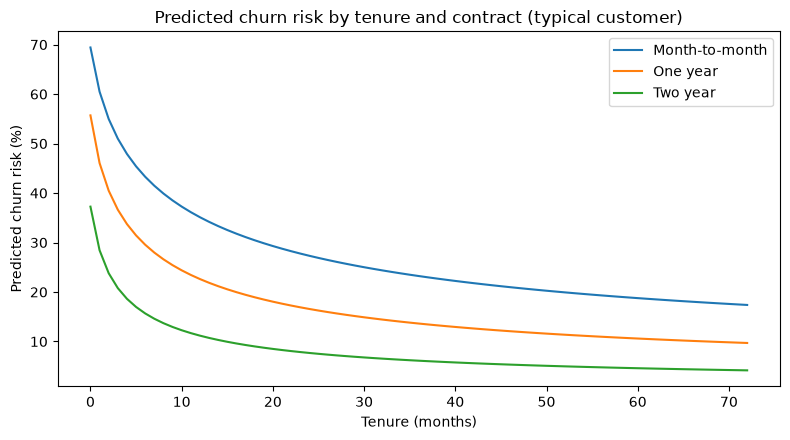

In [50]:
# For each tenure value, set EVERY training customer to that tenure (and contract), predict,
# and average: "the typical customer's risk", with all other features as they really are.
months = np.arange(0, 73)
fig, ax = plt.subplots(figsize=(8, 4.5))
for contract in contract_order:
    risk = []
    for t in months:
        X_t = X_train.assign(tenure=t, log_tenure=np.log1p(t), Contract=contract)
        risk.append(final_model.predict_proba(X_t)[:, 1].mean() * 100)
    ax.plot(months, risk, label=contract)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Predicted churn risk (%)")
ax.set_title("Predicted churn risk by tenure and contract (typical customer)")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "step7_risk_by_tenure_contract.png", dpi=200)
plt.show()

### What-if risks in plain numbers
Average predicted risk for the **same** test customers, changing one factor at a time. These are associations from the model, not causal effects.

In [51]:
# Plain-language effects: average predicted churn risk for the SAME customers, changing only one thing
def avg_risk(data, **changes):
    X = data.assign(**changes)
    if "tenure" in changes:                              # keep log tenure consistent with tenure
        X["log_tenure"] = np.log1p(X["tenure"])
    return final_model.predict_proba(X)[:, 1].mean()

base = X_test                                            # the 1,409 customers the model never saw
internet = X_test[X_test["InternetService"] != "No"]     # add-on/internet comparisons only make sense for them

effects = {
    "Contract: month-to-month": avg_risk(base, Contract="Month-to-month"),
    "Contract: one year":       avg_risk(base, Contract="One year"),
    "Contract: two year":       avg_risk(base, Contract="Two year"),
    "Tenure: 1 month":          avg_risk(base, tenure=1),
    "Tenure: 12 months":        avg_risk(base, tenure=12),
    "Tenure: 48 months":        avg_risk(base, tenure=48),
    "Internet: DSL (internet customers)":   avg_risk(internet, InternetService="DSL"),
    "Internet: fiber (internet customers)": avg_risk(internet, InternetService="Fiber optic"),
    "Payment: bank transfer (automatic)":   avg_risk(base, PaymentMethod="Bank transfer (automatic)"),
    "Payment: electronic check":            avg_risk(base, PaymentMethod="Electronic check"),
    "Tech support: no (internet customers)":  avg_risk(internet, TechSupport="No"),
    "Tech support: yes (internet customers)": avg_risk(internet, TechSupport="Yes"),
}
print(pd.Series(effects).mul(100).round(1).astype(str).add("%").to_string())

Contract: month-to-month                  31.0%
Contract: one year                        20.2%
Contract: two year                        10.4%
Tenure: 1 month                           49.8%
Tenure: 12 months                         28.0%
Tenure: 48 months                         16.2%
Internet: DSL (internet customers)        23.1%
Internet: fiber (internet customers)      38.0%
Payment: bank transfer (automatic)        24.7%
Payment: electronic check                 29.4%
Tech support: no (internet customers)     33.5%
Tech support: yes (internet customers)    28.8%


## 8. Business translation
Turns the model into the business answer: **who to contact, with what action, and what it is worth.**
All € figures rest on **assumptions that are not in the data**. They are illustrative. A pilot A/B test (section 9) would replace the weakest one, the offer success rate, with a measured number.

| Assumption | Base | Sensitivity range | Reasoning |
|---|---|---|---|
| Offer success rate (share of contacted would-be churners who stay because of the offer) | 20% | 10–40% | Evidence ranges from ~10% (telecom campaign case) to ~50% (documented test vs control); 20% = cautious headline |
| Value of a retained customer | MonthlyCharges × 12 months × 40% margin | 6–24 months | 12 months = conservative horizon (offer buys time, not lifelong loyalty); 40% ≈ telecom EBITDA margin, conservative for an existing customer |
| Cost per contact (call + average offer) | €30 | €15–50 | No public benchmark; ~10-min call + incentive worth part of a monthly bill |

**Expected value of contacting a customer = P(churn) × success rate × customer value − cost per contact.**
Currency: € (the data does not state a currency).

In [52]:
# BUSINESS ASSUMPTIONS: not in the data, illustrative
SUCCESS_RATE, SUCCESS_RANGE = 0.20, (0.10, 0.40)   # share of contacted would-be churners who stay
VALUE_MONTHS, MONTHS_RANGE = 12, (6, 24)           # months of margin saved per retained customer
MARGIN = 0.40                                      # profit share of monthly revenue
CONTACT_COST, COST_RANGE = 30, (15, 50)            # € per contacted customer (call + average offer)

def customer_value(data, months=VALUE_MONTHS):
    """€ value of keeping a customer: monthly charge x months x margin."""
    return data["MonthlyCharges"] * months * MARGIN

### 8.1 Calibration check: can the probabilities be trusted?
The € calculation multiplies predicted probabilities, so a predicted 60% must really mean about 60%. Checked on out-of-fold training predictions (the decision data) and confirmed on the test set. Points on the diagonal = well calibrated.

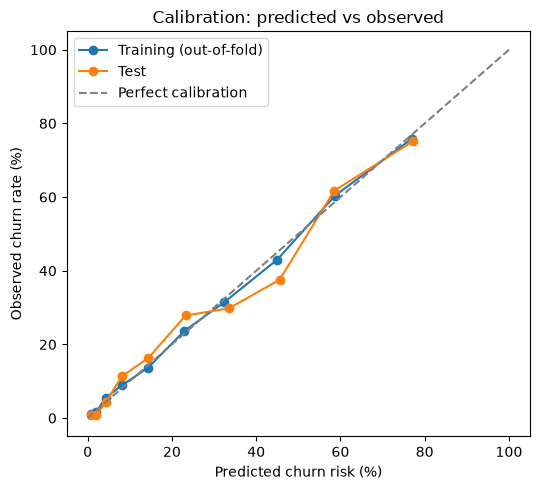

Average predicted risk vs actual churn rate | training (OOF): 0.266 vs 0.265 | test: 0.268 vs 0.265
        customers  predicted  observed
decile                                
D1            141      0.008     0.007
D2            141      0.020     0.007
D3            141      0.042     0.043
D4            141      0.081     0.113
D5            141      0.144     0.163
D6            140      0.233     0.279
D7            141      0.335     0.298
D8            141      0.456     0.376
D9            141      0.585     0.617
D10           141      0.773     0.752


In [53]:
from sklearn.model_selection import cross_val_predict
from sklearn.calibration import calibration_curve

# Out-of-fold predictions on training data: every customer scored by a model that never saw them
p_oof = cross_val_predict(clone(final_model), X_train, y_train, cv=outer_cv, method="predict_proba")[:, 1]

fig, ax = plt.subplots(figsize=(5.5, 5))
for label, y_true, p in [("Training (out-of-fold)", y_train, p_oof), ("Test", y_test, p_test)]:
    observed, predicted = calibration_curve(y_true, p, n_bins=10, strategy="quantile")  # 10 equal-sized groups
    ax.plot(predicted * 100, observed * 100, marker="o", label=label)
ax.plot([0, 100], [0, 100], "--", color="grey", label="Perfect calibration")
ax.set_xlabel("Predicted churn risk (%)")
ax.set_ylabel("Observed churn rate (%)")
ax.set_title("Calibration: predicted vs observed")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "step8_calibration.png", dpi=200)
plt.show()

print(f"Average predicted risk vs actual churn rate | training (OOF): {p_oof.mean():.3f} vs {y_train.mean():.3f}"
      f" | test: {p_test.mean():.3f} vs {y_test.mean():.3f}")

# Test set by risk decile: does predicted match observed in each group?
deciles = pd.qcut(p_test, 10, labels=[f"D{i}" for i in range(1, 11)])
calib = pd.DataFrame({"risk": p_test, "churn": y_test.values, "decile": deciles}).groupby("decile", observed=True)
print(calib.agg(customers=("churn", "size"), predicted=("risk", "mean"), observed=("churn", "mean"))
      .round(3).to_string())

### 8.2 Budget table: what each contact budget delivers (test set)
Budgets are **illustrative** (the client's real capacity is unknown): the client picks the budget, the model says who to call.

In [54]:
order_risk = np.argsort(-p_test, kind="stable")          # highest risk first
y_sorted = y_test.values[order_risk]
budget_rows = []
for share in [0.10, 0.20, 0.30]:
    n = int(round(share * len(y_test)))
    caught = int(y_sorted[:n].sum())
    budget_rows.append({"Budget (% contacted)": f"{share:.0%}", "Customers contacted": n,
                        "Churners reached": caught,
                        "% of all churners": f"{caught / y_test.sum():.0%}",
                        "Hit rate": f"{caught / n:.0%}",
                        "Lift vs random": f"{(caught / n) / y_test.mean():.1f}x"})
print(pd.DataFrame(budget_rows).to_string(index=False))
print(f"\nRandom selection hit rate = churn rate = {y_test.mean():.0%}; test set = {len(y_test):,} customers, "
      f"{int(y_test.sum())} churners")

Budget (% contacted)  Customers contacted  Churners reached % of all churners Hit rate Lift vs random
                 10%                  141               106               28%      75%           2.8x
                 20%                  282               193               52%      68%           2.6x
                 30%                  423               246               66%      58%           2.2x

Random selection hit rate = churn rate = 27%; test set = 1,409 customers, 374 churners


### 8.3 Profit curve: how many customers to contact?
Back-test on the test set: if the team had contacted the top *N* customers, what would the campaign have been worth? Value comes only from **real churners** reached (× success rate × customer value); every contact costs €30.
Two ways to rank: by **churn risk**, or by **expected value** (risk × customer value, so valuable customers move up). Compared with random selection and the pre-committed rule. The shaded band shows the success rate between 10% and 40%.

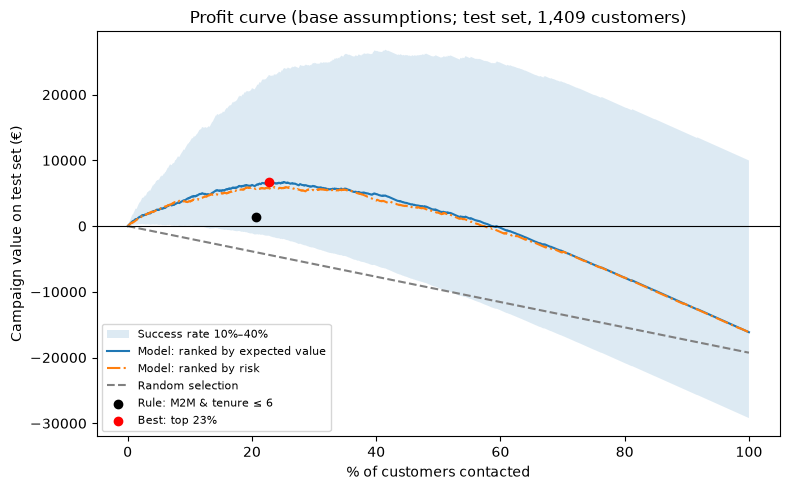

                     Approach  Best list size Best % contacted  Best value (€)  Value at 20% (€)  Best value per 1,000 customers (€)
Model, expected-value ranking             320              23%            6700              6259                                4755
          Model, risk ranking             334              24%            5952              5828                                4224

Rule (M2M & tenure ≤ 6): 291 customers (21%) -> €1,448 | model (EV ranking) at the same list size -> €6,209 | random at the same size -> €-3,978


In [55]:
mc_test = X_test["MonthlyCharges"].values
y_arr = y_test.values

def profit_curve(order, success=SUCCESS_RATE, months=VALUE_MONTHS, cost=CONTACT_COST):
    """Cumulative € value when contacting customers in the given order (index 0 = nobody contacted)."""
    value = mc_test * months * MARGIN
    gain = y_arr[order] * success * value[order] - cost
    return np.concatenate([[0.0], np.cumsum(gain)])

# Ranking by expected value: risk x customer value (success, months and cost don't change the order)
order_ev = np.argsort(-(p_test * mc_test), kind="stable")
n_axis = np.arange(len(y_arr) + 1)
pct_axis = n_axis / len(y_arr) * 100

curve_ev, curve_risk = profit_curve(order_ev), profit_curve(order_risk)
# Random selection: on average each contact reaches churn-rate x average value
random_line = n_axis * (y_arr.mean() * SUCCESS_RATE * (mc_test * VALUE_MONTHS * MARGIN).mean() - CONTACT_COST)
rule_flag = business_rule(X_test).values.astype(bool)
rule_n = int(rule_flag.sum())
rule_value = (y_arr[rule_flag] * SUCCESS_RATE * mc_test[rule_flag] * VALUE_MONTHS * MARGIN).sum() - CONTACT_COST * rule_n

fig, ax = plt.subplots(figsize=(8, 5))
low, high = profit_curve(order_ev, success=SUCCESS_RANGE[0]), profit_curve(order_ev, success=SUCCESS_RANGE[1])
ax.fill_between(pct_axis, low, high, alpha=0.15, label=f"Success rate {SUCCESS_RANGE[0]:.0%}–{SUCCESS_RANGE[1]:.0%}")
ax.plot(pct_axis, curve_ev, label="Model: ranked by expected value")
ax.plot(pct_axis, curve_risk, label="Model: ranked by risk", linestyle="-.")
ax.plot(pct_axis, random_line, "--", color="grey", label="Random selection")
ax.scatter([rule_n / len(y_arr) * 100], [rule_value], color="black", zorder=5, label="Rule: M2M & tenure ≤ 6")
best = int(np.argmax(curve_ev))
ax.scatter([pct_axis[best]], [curve_ev[best]], color="red", zorder=6, label=f"Best: top {pct_axis[best]:.0f}%")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("% of customers contacted")
ax.set_ylabel("Campaign value on test set (€)")
ax.set_title("Profit curve (base assumptions; test set, 1,409 customers)")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "step8_profit_curve.png", dpi=200)
plt.show()

def summarise(curve, name):
    b = int(np.argmax(curve)); n20 = int(round(0.20 * len(y_arr)))
    return {"Approach": name, "Best list size": b, "Best % contacted": f"{b / len(y_arr):.0%}",
            "Best value (€)": round(curve[b]), "Value at 20% (€)": round(curve[n20]),
            "Best value per 1,000 customers (€)": round(curve[b] / len(y_arr) * 1000)}
summary_rows = [summarise(curve_ev, "Model, expected-value ranking"), summarise(curve_risk, "Model, risk ranking")]
print(pd.DataFrame(summary_rows).to_string(index=False))
print(f"\nRule (M2M & tenure ≤ 6): {rule_n} customers ({rule_n / len(y_arr):.0%}) -> €{rule_value:,.0f}"
      f" | model (EV ranking) at the same list size -> €{curve_ev[rule_n]:,.0f}"
      f" | random at the same size -> €{random_line[rule_n]:,.0f}")

How many leavers does the best list reach, and how does it compare with the rule at the same list size?

In [56]:
best = int(np.argmax(curve_ev))
reached = int(y_arr[order_ev[:best]].sum())
print(f"Top {best} by risk × value: {reached} real leavers reached "
      f"({reached / y_arr.sum():.0%} of all), about {reached * SUCCESS_RATE:.0f} expected to be saved")

Top 320 by risk × value: 198 real leavers reached (53% of all), about 40 expected to be saved


In [57]:
ev_reached = int(y_arr[order_ev[:rule_n]].sum())
print(f"Same {rule_n} calls → model (risk × value): {ev_reached} leavers | model (risk only): "
      f"{churners_caught(y_test, p_test, rule_n)} | rule: {int(y_arr[rule_flag].sum())} | "
      f"random (expected): {rule_n * y_arr.mean():.0f}")

Same 291 calls → model (risk × value): 182 leavers | model (risk only): 194 | rule: 170 | random (expected): 77


### 8.4 Sensitivity: how much does the answer depend on the assumptions?
One assumption varied at a time (others at base), plus a pessimistic and an optimistic combination. Model ranked by expected value, test set.

In [58]:
scenarios = {"Base": {}}
for s in SUCCESS_RANGE: scenarios[f"Success {s:.0%}"] = {"success": s}
for m in MONTHS_RANGE:  scenarios[f"Value horizon {m} months"] = {"months": m}
for c in COST_RANGE:    scenarios[f"Cost €{c}"] = {"cost": c}
scenarios["Pessimistic (10%, 6 months, €50)"] = {"success": SUCCESS_RANGE[0], "months": MONTHS_RANGE[0], "cost": COST_RANGE[1]}
scenarios["Optimistic (40%, 24 months, €15)"] = {"success": SUCCESS_RANGE[1], "months": MONTHS_RANGE[1], "cost": COST_RANGE[0]}

sens_rows = []
n20 = int(round(0.20 * len(y_arr)))
for name, kw in scenarios.items():
    curve = profit_curve(order_ev, **kw)
    b = int(np.argmax(curve))
    sens_rows.append({"Scenario": name, "Best % contacted": f"{b / len(y_arr):.0%}",
                      "Best value (€)": round(curve[b]), "Value at 20% (€)": round(curve[n20]),
                      "Per 1,000 customers at best (€)": round(curve[b] / len(y_arr) * 1000)})
print(pd.DataFrame(sens_rows).to_string(index=False))

                        Scenario Best % contacted  Best value (€)  Value at 20% (€)  Per 1,000 customers at best (€)
                            Base              23%            6700              6259                             4755
                     Success 10%               2%             338             -1101                              240
                     Success 40%              41%           26825             20977                            19039
          Value horizon 6 months               2%             338             -1101                              240
         Value horizon 24 months              41%           26825             20977                            19039
                        Cost €15              41%           13413             10489                             9519
                        Cost €50              12%            1629               619                             1156
Pessimistic (10%, 6 months, €50)               0%               

### 8.5 Tiers and actions
The tier cut-offs follow the profit curve:
- **Call** = top 23% by risk × value (the most profitable list at €30 per contact).
- **CRM email/SMS** = up to 40% (the optimum when a contact costs about €15; see the sensitivity table).
- **No outreach** = the rest.

The tier profile shows *why* the listed customers are risky, which suggests the action.

In [59]:
# Tiers aligned with the profit curve
CALL_CUT, CRM_CUT = 0.23, 0.40
TIER_LABELS = ["Call", "CRM", "No outreach"]

# 1) Test set: tiers by position in the risk x value ranking, and the tier profile
rank = pd.Series(np.empty(len(y_arr)), index=X_test.index)
rank.iloc[order_ev] = np.arange(1, len(y_arr) + 1) / len(y_arr)
tier = pd.cut(rank, bins=[0, CALL_CUT, CRM_CUT, 1.0], labels=TIER_LABELS)

seg = X_test.assign(risk=p_test, churn=y_arr, tier=tier)
has_internet = seg["InternetService"] != "No"
g = seg.groupby("tier", observed=True)
profile = pd.DataFrame({
    "Customers": g.size(),
    "Avg predicted risk": g["risk"].mean(),
    "Actual churn rate": g["churn"].mean(),
    "Month-to-month": g["Contract"].apply(lambda s: (s == "Month-to-month").mean()),
    "Tenure <= 6 months": g["tenure"].apply(lambda s: (s <= 6).mean()),
    "Fiber": g["InternetService"].apply(lambda s: (s == "Fiber optic").mean()),
    "Electronic check": g["PaymentMethod"].apply(lambda s: (s == "Electronic check").mean()),
    "No tech support (internet cust.)": seg[has_internet].groupby("tier", observed=True)["TechSupport"]
                                         .apply(lambda s: (s == "No").mean()),
    "Avg monthly charge (€)": g["MonthlyCharges"].mean(),
}).T
print("Tier profile (test set):")
print(profile.round(2).to_string())

Tier profile (test set):
tier                                Call     CRM  No outreach
Customers                         324.00  239.00       846.00
Avg predicted risk                  0.63    0.38         0.10
Actual churn rate                   0.61    0.35         0.11
Month-to-month                      0.98    0.77         0.32
Tenure <= 6 months                  0.43    0.27         0.13
Fiber                               0.99    0.63         0.17
Electronic check                    0.69    0.47         0.16
No tech support (internet cust.)    0.88    0.75         0.44
Avg monthly charge (€)             86.91   75.96        51.99


**Suggested actions per driver** (hypotheses to test, not proven effects):

| Driver in the list | Suggested action | Linked finding |
|---|---|---|
| Month-to-month, especially in the first months | Early-life programme: check-in call + offer to move to a 1- or 2-year contract | H1, H2 |
| Fiber customers | Service check: find out whether price or service drives fiber churn | H3 (price and product can't be separated in this data) |
| No online security / tech support | Free tech-support trial (what-if risk 34% → 29%) | H4 |
| Electronic check | Incentive to switch to automatic payment (what-if risk 29% → 25%) | H5 |

### 8.6 Contact list (deliverable format)
In production, the model scores all **active** customers each month. Here, the active customers in the dataset are scored, sorted by expected value and assigned a tier. The list is saved to `outputs/results/contact_list.csv`. Training customers are scored by a model that saw them, so this list shows the format, not a performance estimate.

In [60]:
active = clean_features(df)
active = active[active[TARGET] == 0].drop(columns=TARGET)              # only customers who are still here
risk_active = final_model.predict_proba(active)[:, 1]
contact = pd.DataFrame({
    "churn_risk": risk_active.round(3),
    "monthly_charge": active["MonthlyCharges"],
    "expected_value_eur": (risk_active * SUCCESS_RATE * customer_value(active) - CONTACT_COST).round(0),
    "contract": active["Contract"], "tenure": active["tenure"],
    "internet": active["InternetService"], "payment": active["PaymentMethod"],
}, index=active.index).sort_values("expected_value_eur", ascending=False)
position = np.arange(1, len(contact) + 1) / len(contact)
contact["tier"] = pd.cut(position, bins=[0, CALL_CUT, CRM_CUT, 1.0], labels=TIER_LABELS)
contact.to_csv(RESULTS_DIR / "contact_list.csv")
print(f"Active customers scored: {len(contact):,} | tiers: {contact['tier'].value_counts().to_dict()}")
print(contact.head(10).to_string())

Active customers scored: 5,174 | tiers: {'No outreach': 3105, 'Call': 1190, 'CRM': 879}
            churn_risk  monthly_charge  expected_value_eur        contract  tenure     internet                  payment  tier
customerID                                                                                                                    
5150-ITWWB       0.880           94.85                50.0  Month-to-month       3  Fiber optic         Electronic check  Call
1393-IMKZG       0.856           95.85                49.0  Month-to-month       1  Fiber optic         Electronic check  Call
2081-VEYEH       0.762          107.95                49.0  Month-to-month       3  Fiber optic         Electronic check  Call
5760-IFJOZ       0.756          107.95                48.0  Month-to-month       3  Fiber optic             Mailed check  Call
6734-GMPVK       0.767          105.30                48.0  Month-to-month       5  Fiber optic         Electronic check  Call
7398-SKNQZ       0.841 

### 8.7 Fairness check: is the contact list skewed by gender or age?
Gender and SeniorCitizen are **not** model inputs, but they are kept to audit the outcome (decision 4.6). Compared: share in the "Call + CRM" list vs share among all test customers, and the hit rate within the list.

In [61]:
# Fairness check on the Call + CRM list (test set)
audit = X_test.assign(churn=y_arr, in_list=(tier != "No outreach").values)
rows = []
for col, groups in [("gender", ["Female", "Male"]), ("SeniorCitizen", [0, 1])]:
    for grp_value in groups:
        grp = audit[audit[col] == grp_value]
        rows.append({"Attribute": col, "Group": grp_value,
                     "Share of all test customers": f"{len(grp) / len(audit):.0%}",
                     "Share of contact list": f"{grp['in_list'].sum() / audit['in_list'].sum():.0%}",
                     "Hit rate in list": f"{grp.loc[grp['in_list'], 'churn'].mean():.0%}"})
print("\nFairness check (Call + CRM list):")
print(pd.DataFrame(rows).to_string(index=False))


Fairness check (Call + CRM list):
    Attribute  Group Share of all test customers Share of contact list Hit rate in list
       gender Female                         49%                   50%              52%
       gender   Male                         51%                   50%              48%
SeniorCitizen      0                         84%                   73%              48%
SeniorCitizen      1                         16%                   27%              56%


### 8.7 Headline numbers and exported curves
Prints every headline number and saves the test-set gains and profit curves to `outputs/results/`.

In [62]:
# Export the test-set curves
x_pct, y_pct = gains(y_test, p_test)
pd.DataFrame({"pct_contacted": x_pct, "pct_churners_reached": y_pct}).to_csv(RESULTS_DIR / "gains_test.csv", index=False)
pd.DataFrame({"pct_contacted": pct_axis, "model_ev_ranking": curve_ev, "model_risk_ranking": curve_risk,
              "random": random_line, "band_low_10pct": low, "band_high_40pct": high}).to_csv(
    RESULTS_DIR / "profit_curve_test.csv", index=False)

# Headline numbers
n20 = int(round(0.20 * len(y_test)))
best_ev, best_risk = int(np.argmax(curve_ev)), int(np.argmax(curve_risk))
print("CV (nested):", cv_means.round(3).to_dict())
print("Test:", {k: round(v, 3) for k, v in test_metrics.items()})
print(f"Top 20%: {n_top} customers, {caught_top} churners ({caught_top / n_top:.0%} hit)")
print(f"Rule list {rule_n}: model {churners_caught(y_test, p_test, rule_n)} vs rule {int(y_test.values[rule_flag].sum())}")
print(f"Profit best (EV ranking): top {best_ev / len(y_arr):.0%} ({best_ev}) → €{curve_ev[best_ev]:,.0f}"
      f" (€{curve_ev[best_ev] / len(y_arr) * 1000:,.0f} per 1,000) | at 20%: €{curve_ev[n20]:,.0f}")
print(f"Profit best (risk ranking): €{curve_risk[best_risk]:,.0f}")
print(f"Same {rule_n} calls: model €{curve_ev[rule_n]:,.0f} | rule €{rule_value:,.0f} | random €{random_line[rule_n]:,.0f}")
print("Saved:", *sorted(p.name for p in RESULTS_DIR.iterdir()))

CV (nested): {'ROC-AUC': 0.85, 'PR-AUC': 0.674, 'log-loss': 0.411, '% churners caught, top 20%': 0.512}
Test: {'ROC-AUC': 0.847, 'PR-AUC': 0.665, 'log-loss': 0.413, '% churners caught, top 20%': np.float64(0.516)}
Top 20%: 282 customers, 193 churners (68% hit)
Rule list 291: model 194 vs rule 170
Profit best (EV ranking): top 23% (320) → €6,700 (€4,755 per 1,000) | at 20%: €6,259
Profit best (risk ranking): €5,952
Same 291 calls: model €6,209 | rule €1,448 | random €-3,978
Saved: contact_list.csv gains_test.csv profit_curve_test.csv test_ids.csv


## 9. Limitations and next steps
**Limitations**
- **One snapshot:** no dates, so the score is resemblance to past leavers, not a time-based forecast, and no time-based validation is possible.
- **€ values rest on assumptions:** the offer success rate drives the answer. At 10% success only the top ~2% pays off; at 40%, contacting ~40% does.
- **High risk ≠ persuadable:** the model finds likely leavers, not customers whom an offer would change.

**Next steps**
1. **A/B pilot (4–6 weeks):** offer vs no offer within the Call tier. The difference in churn is the real success rate.
2. **Set the list size:** feed the measured success rate into the profit curve.
3. **Run monthly:** score active customers every month, and compare last month's list with who actually left.
4. **Collect the right data:** log offers and responses, so a later model can target who *responds* (uplift), not just who leaves.